In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import copy
import random
import math
import numpy as np
import pandas as pd

# Your project imports
from tsn_scheduling_problem import TSNScheduling
from schedule import Schedule, Slot

# Benchmark utilities you already have
from benchmark_utils import (
    build_network_generator_from_usecase,
    generate_one_arrival_stream,
    build_usecase_stream_from_request,
)

# Optional: cleaner printing
np.set_printoptions(suppress=True, linewidth=140)

print("Imports loaded.")

Imports loaded.


In [3]:
CONFIG_PATH = "uc_config.cfg"
INSTANCE_PATH = "banana3.json"   # change if you want another instance

problem = TSNScheduling(CONFIG_PATH)
instance = problem.import_scheduling_usecase(INSTANCE_PATH)

# Keep problem aligned with this instance
problem.usecase = instance
problem.build_metadata()

print("Loaded instance:", INSTANCE_PATH)
print("Number of streams in usecase:", len(instance.streams))
print("Number of scheduled slots:", len(instance.schedule))

active_stream_ids = sorted({
    int(slot.stream_id)
    for slot in instance.schedule
    if slot.stream_id is not None
})

print("Active scheduled streams:", len(active_stream_ids))
print("Active stream IDs:", active_stream_ids)
print("Cycle ns:", instance.schedule.cycle_ns)

Loaded instance: banana3.json
Number of streams in usecase: 62
Number of scheduled slots: 18
Active scheduled streams: 5
Active stream IDs: [4, 14, 23, 24, 38]
Cycle ns: 300000


In [4]:
from evaluator import TSNConstraintEvaluator, ScheduleEncodingType

def check_schedule_validity(instance, problem, label="schedule"):
    """
    Check whether the current instance.schedule has evaluator violations.
    """
    problem.usecase = instance
    problem.build_metadata()

    evaluator = TSNConstraintEvaluator(
        problem,
        check_routing=False,
        check_task_placement=False,
        scheduling_type=ScheduleEncodingType.START_TIME,
    )

    compact = instance.schedule.to_compact_encoding(
        problem.n_ports,
        problem.n_streams,
    )

    violations = evaluator.per_stream_all_violations(compact)

    breakdown = {
        "seq": int(violations[0].sum()) if violations.shape[0] > 0 else 0,
        "fifo": int(violations[1].sum()) if violations.shape[0] > 1 else 0,
        "macrocycle": int(violations[2].sum()) if violations.shape[0] > 2 else 0,
        "talker_offset": int(violations[3].sum()) if violations.shape[0] > 3 else 0,
        "latency": int(violations[4].sum()) if violations.shape[0] > 4 else 0,
        "total": int(violations.sum()),
    }

    print(f"[{label}] violation breakdown:", breakdown)
    return breakdown

validity = check_schedule_validity(instance, problem, label="initial")

[initial] violation breakdown: {'seq': 0, 'fifo': 0, 'macrocycle': 0, 'talker_offset': 0, 'latency': 0, 'total': 0}


In [5]:
DRL_MODEL_PATH_V27 = "runs/0/run_41_trace_env_smoke/best_model"

DRL_TRAIN_CONFIG_V27 = {
    "max_candidates": 10,
    "max_hops": 6,
    "max_steps": 500,

    "init_from_usecase_schedule": True,
    "include_current_offset_candidate": True,

    "per_hop_candidate_limit": 5,
    "beam_width": 30,

    "defrag_cycle_penalty": 0.6,
    "reallocation_penalty": 0.1,
    "invalid_penalty": 10.0,

    "useless_gap_threshold_bytes": 1024,
    "expected_incoming_bytes": 1024,

    "top_k_oldest_random": 10,
}

In [6]:
from stable_baselines3 import DQN
from env import TSNCandidatePathEnv


def make_drl_eval_env(
    instance,
    problem,
    seed=42,
    lambda_arrival=0.75,
    decision_points_per_episode=300,
    cfg=None,
):
    cfg = cfg or DRL_TRAIN_CONFIG_V27

    prob = copy.deepcopy(problem)
    inst = copy.deepcopy(instance)
    prob.usecase = inst
    prob.build_metadata()

    env = TSNCandidatePathEnv(
        problem=prob,
        usecase=inst,
        useless_gap_threshold_bytes=cfg["useless_gap_threshold_bytes"],
        expected_incoming_bytes=cfg["expected_incoming_bytes"],
        invalid_penalty=cfg["invalid_penalty"],
        max_candidates=cfg["max_candidates"],
        max_steps=cfg["max_steps"],
        max_hops=cfg["max_hops"],
        init_from_usecase_schedule=cfg["init_from_usecase_schedule"],
        include_current_offset_candidate=cfg["include_current_offset_candidate"],
        per_hop_candidate_limit=cfg["per_hop_candidate_limit"],
        beam_width=cfg["beam_width"],
        defrag_cycle_penalty=cfg["defrag_cycle_penalty"],
        reallocation_penalty=cfg["reallocation_penalty"],
        lambda_arrival=lambda_arrival,
        mu_departure=1.0,  # not very important for shared-trace mode, but keep stable
        dt=1.0,
        decision_points_per_episode=decision_points_per_episode,
        top_k_oldest_random=cfg["top_k_oldest_random"],
        seed=seed,
    )

    return env


def check_drl_model_env_compatibility(model_path, instance, problem, cfg=None):
    env = make_drl_eval_env(
        instance=instance,
        problem=problem,
        seed=42,
        lambda_arrival=0.75,
        decision_points_per_episode=300,
        cfg=cfg,
    )

    model = DQN.load(model_path)

    print("Model observation space:")
    print(model.observation_space)

    print("\nEval env observation space:")
    print(env.observation_space)

    print("\nModel action space:")
    print(model.action_space)

    print("\nEval env action space:")
    print(env.action_space)

    print("\nObservation spaces equal:", model.observation_space == env.observation_space)
    print("Action spaces equal:", model.action_space == env.action_space)

    return model, env

model_check, env_check = check_drl_model_env_compatibility(
    model_path=DRL_MODEL_PATH_V27,
    instance=instance,
    problem=problem,
    cfg=DRL_TRAIN_CONFIG_V27,
)

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


Model observation space:
Dict('base_features': Box(-1.0, 1.0, (7,), float32), 'candidate_features': Box(-1.0, 1.0, (5, 4), float32), 'candidate_mask': Box(0, 1, (6,), int8), 'candidate_offsets': Box(-1.0, 1.0, (5, 6), float32), 'current_offsets': Box(-1.0, 1.0, (6,), float32))

Eval env observation space:
Dict('base_features': Box(-1.0, 1.0, (7,), float32), 'candidate_features': Box(-1.0, 1.0, (10, 4), float32), 'candidate_mask': Box(0, 1, (11,), int8), 'candidate_offsets': Box(-1.0, 1.0, (10, 6), float32), 'current_offsets': Box(-1.0, 1.0, (6,), float32))

Model action space:
Discrete(6)

Eval env action space:
Discrete(11)

Observation spaces equal: False
Action spaces equal: False


In [7]:
def generate_long_decision_trace(
    instance,
    max_steps=10000,
    lambda_arrival=1.0,
    dt=1.0,
    seed=42,
    ed_ed_settings=None,
):
    """
    Generate a long shared trace for decision-point experiments.

    Each step contains:
      - n_dep = 1 departure opportunity
      - arrivals sampled from Poisson(lambda_arrival * dt)

    The runner decides when to stop based on actual departures.
    """
    rng_np = np.random.default_rng(seed)

    ng = build_network_generator_from_usecase(copy.deepcopy(instance))

    trace = []

    for _ in range(int(max_steps)):
        n_arr = int(rng_np.poisson(lambda_arrival * dt))

        arrivals = []
        for _ in range(n_arr):
            raw_stream = generate_one_arrival_stream(
                ng,
                ed_ed_settings=ed_ed_settings,
            )
            arrivals.append(raw_stream)

        trace.append({
            "n_dep": 1,
            "arrivals": arrivals,
        })

    return trace

In [8]:
def get_active_stream_ids(schedule):
    return sorted({
        int(slot.stream_id)
        for slot in schedule
        if slot.stream_id is not None
    })


def build_port_intervals(schedule):
    relevant_ports = sorted({
        int(slot.port_id)
        for slot in schedule
        if slot.port_id is not None
    })

    return {
        pid: schedule._occupied_intervals_on_port(pid, schedule.cycle_ns)
        for pid in relevant_ports
    }


def init_stream_arrival_times(schedule):
    """
    Initial streams are considered already present at time 0.
    """
    return {
        int(sid): 0.0
        for sid in get_active_stream_ids(schedule)
    }


def summarize_decisions(decisions):
    """
    decisions maps arrival_id -> one of:
      accept, scheduler_reject, raw_none, build_none
    """
    counts = {
        "accept": 0,
        "scheduler_reject": 0,
        "raw_none": 0,
        "build_none": 0,
    }

    for v in decisions.values():
        if v in counts:
            counts[v] += 1
        else:
            counts[v] = counts.get(v, 0) + 1

    return counts


def batch_left_compact_streams_preserve_id(
    schedule,
    stream_ids,
    usecase,
    problem,
    queue_id=5,
    port_intervals=None,
    max_candidates_per_hop=2,
    beam_width=1,
):
    """
    Clean batch left-compaction with preserved stream IDs.

    Steps:
      1. Backup full schedule and stream metadata.
      2. Remove all selected stream slots as a batch.
      3. Reinsert each selected stream using preserve-ID first-fit-fast.
      4. If any stream fails, rollback everything.
      5. Return moved stream IDs.
    """
    import copy

    stream_ids = [int(sid) for sid in stream_ids]

    if not stream_ids:
        return {
            "success": True,
            "moved_stream_ids": [],
            "failed_stream_ids": [],
        }

    # Full backup for rollback
    old_schedule_slots = copy.deepcopy(list(schedule))
    old_streams = copy.deepcopy(usecase.streams)

    old_offsets = {
        sid: sorted(
            int(slot.start_ns)
            for slot in schedule
            if slot.stream_id is not None and int(slot.stream_id) == sid
        )
        for sid in stream_ids
    }

    # Check all streams exist and are scheduled
    for sid in stream_ids:
        if sid < 0 or sid >= len(usecase.streams):
            return {
                "success": False,
                "moved_stream_ids": [],
                "failed_stream_ids": [sid],
            }

        if not old_offsets.get(sid):
            return {
                "success": False,
                "moved_stream_ids": [],
                "failed_stream_ids": [sid],
            }

    selected_set = set(stream_ids)

    # Remove all selected stream slots together
    schedule[:] = [
        slot for slot in schedule
        if slot.stream_id is None or int(slot.stream_id) not in selected_set
    ]
    schedule.sort()

    # Rebuild intervals after batch removal
    if port_intervals is not None:
        port_intervals.clear()
        port_intervals.update(build_port_intervals(schedule))

    problem.usecase = usecase
    problem.build_metadata()

    failed_stream_ids = []

    for sid in stream_ids:
        result = schedule.place_existing_stream_first_fit_fast(
            stream_id=sid,
            usecase=usecase,
            problem=problem,
            queue_id=queue_id,
            port_intervals=port_intervals,
            max_candidates_per_hop=max_candidates_per_hop,
            beam_width=beam_width,
        )

        if not result.get("accepted"):
            failed_stream_ids.append(sid)
            break

    if failed_stream_ids:
        # Full rollback
        schedule[:] = old_schedule_slots
        schedule.sort()

        usecase.streams = old_streams

        problem.usecase = usecase
        problem.build_metadata()

        if port_intervals is not None:
            port_intervals.clear()
            port_intervals.update(build_port_intervals(schedule))

        usecase.removeSchedule()
        _, port_id_to_name = usecase.port_name_id_mapping
        usecase.schedule = schedule
        schedule.update_graph(usecase.graph, port_id_to_name)

        return {
            "success": False,
            "moved_stream_ids": [],
            "failed_stream_ids": failed_stream_ids,
        }

    # Count real moved streams
    moved_stream_ids = []

    for sid in stream_ids:
        new_offsets = sorted(
            int(slot.start_ns)
            for slot in schedule
            if slot.stream_id is not None and int(slot.stream_id) == sid
        )

        if old_offsets.get(sid, []) != new_offsets:
            moved_stream_ids.append(sid)

    usecase.removeSchedule()
    _, port_id_to_name = usecase.port_name_id_mapping
    usecase.schedule = schedule
    schedule.update_graph(usecase.graph, port_id_to_name)

    return {
        "success": True,
        "moved_stream_ids": moved_stream_ids,
        "failed_stream_ids": [],
    }


def batch_right_compact_streams_preserve_id(
    schedule,
    stream_ids,
    usecase,
    problem,
    queue_id=5,
    port_intervals=None,
    max_candidates_per_hop=5,
    beam_width=3,
):
    """
    Clean batch right-compaction with preserved stream IDs.

    Steps:
      1. Backup full schedule and stream metadata.
      2. Remove all selected stream slots as a batch.
      3. Reinsert each selected stream using preserve-ID right-fit.
      4. If any stream fails, rollback everything.
      5. Return moved stream IDs.
    """
    import copy

    stream_ids = [int(sid) for sid in stream_ids]

    if not stream_ids:
        return {
            "success": True,
            "moved_stream_ids": [],
            "failed_stream_ids": [],
        }

    old_schedule_slots = copy.deepcopy(list(schedule))
    old_streams = copy.deepcopy(usecase.streams)

    old_offsets = {
        sid: sorted(
            int(slot.start_ns)
            for slot in schedule
            if slot.stream_id is not None and int(slot.stream_id) == sid
        )
        for sid in stream_ids
    }

    for sid in stream_ids:
        if sid < 0 or sid >= len(usecase.streams):
            return {
                "success": False,
                "moved_stream_ids": [],
                "failed_stream_ids": [sid],
            }

        if not old_offsets.get(sid):
            return {
                "success": False,
                "moved_stream_ids": [],
                "failed_stream_ids": [sid],
            }

    selected_set = set(stream_ids)

    schedule[:] = [
        slot for slot in schedule
        if slot.stream_id is None or int(slot.stream_id) not in selected_set
    ]
    schedule.sort()

    if port_intervals is not None:
        port_intervals.clear()
        port_intervals.update(build_port_intervals(schedule))

    problem.usecase = usecase
    problem.build_metadata()

    failed_stream_ids = []

    for sid in stream_ids:
        result = schedule.place_existing_stream_right_fit_backward(
            stream_id=sid,
            usecase=usecase,
            problem=problem,
            queue_id=queue_id,
            port_intervals=port_intervals,
            max_candidates_per_hop=max_candidates_per_hop,
            beam_width=beam_width,
        )

        if not result.get("accepted"):
            failed_stream_ids.append(sid)
            break

    if failed_stream_ids:
        schedule[:] = old_schedule_slots
        schedule.sort()

        usecase.streams = old_streams

        problem.usecase = usecase
        problem.build_metadata()

        if port_intervals is not None:
            port_intervals.clear()
            port_intervals.update(build_port_intervals(schedule))

        usecase.removeSchedule()
        _, port_id_to_name = usecase.port_name_id_mapping
        usecase.schedule = schedule
        schedule.update_graph(usecase.graph, port_id_to_name)

        return {
            "success": False,
            "moved_stream_ids": [],
            "failed_stream_ids": failed_stream_ids,
        }

    moved_stream_ids = []

    for sid in stream_ids:
        new_offsets = sorted(
            int(slot.start_ns)
            for slot in schedule
            if slot.stream_id is not None and int(slot.stream_id) == sid
        )

        if old_offsets.get(sid, []) != new_offsets:
            moved_stream_ids.append(sid)

    usecase.removeSchedule()
    _, port_id_to_name = usecase.port_name_id_mapping
    usecase.schedule = schedule
    schedule.update_graph(usecase.graph, port_id_to_name)

    return {
        "success": True,
        "moved_stream_ids": moved_stream_ids,
        "failed_stream_ids": [],
    }


def oldest_first_left_compact_defrag_preserve_id(
    schedule,
    usecase,
    problem,
    p,
    n,
    departure_counter,
    queue_id=5,
    port_intervals=None,
    stream_arrival_times=None,
    max_candidates_per_hop=2,
    beam_width=1,
):
    """
    OF-LC(p,n): Oldest-First Left-Compaction with preserved stream IDs.

    Every p departures:
      1. Select n oldest active streams.
      2. Remove them as a batch.
      3. Reinsert them from the left using preserve-ID first-fit-fast.
      4. Roll back if the batch cannot be fully reinserted.
    """
    if p <= 0 or n <= 0:
        return {
            "triggered": False,
            "selected_stream_ids": [],
            "moved_stream_ids": [],
            "replaced_count": 0,
            "success": False,
        }

    if departure_counter == 0 or (departure_counter % p) != 0:
        return {
            "triggered": False,
            "selected_stream_ids": [],
            "moved_stream_ids": [],
            "replaced_count": 0,
            "success": False,
        }

    if stream_arrival_times is None:
        stream_arrival_times = {}

    active_stream_ids = get_active_stream_ids(schedule)

    if not active_stream_ids:
        return {
            "triggered": True,
            "selected_stream_ids": [],
            "moved_stream_ids": [],
            "replaced_count": 0,
            "success": True,
        }

    stream_first_offset = {}
    for sid in active_stream_ids:
        offsets = get_stream_offsets(schedule, sid)
        stream_first_offset[sid] = min(offsets) if offsets else float("inf")

    ordered_stream_ids = sorted(
        active_stream_ids,
        key=lambda sid: (
            float(stream_arrival_times.get(int(sid), float("inf"))),
            float(stream_first_offset.get(int(sid), float("inf"))),
            int(sid),
        ),
    )

    selected_stream_ids = ordered_stream_ids[:min(int(n), len(ordered_stream_ids))]

    result = batch_left_compact_streams_preserve_id(
        schedule=schedule,
        stream_ids=selected_stream_ids,
        usecase=usecase,
        problem=problem,
        queue_id=queue_id,
        port_intervals=port_intervals,
        max_candidates_per_hop=max_candidates_per_hop,
        beam_width=beam_width,
    )

    moved_stream_ids = result.get("moved_stream_ids", []) if result.get("success") else []

    return {
        "triggered": True,
        "selected_stream_ids": selected_stream_ids,
        "moved_stream_ids": moved_stream_ids,
        "replaced_count": len(moved_stream_ids),
        "success": result.get("success", False),
        "failed_stream_ids": result.get("failed_stream_ids", []),
    }


def oldest_first_right_compact_defrag_preserve_id(
    schedule,
    usecase,
    problem,
    p,
    n,
    departure_counter,
    queue_id=5,
    port_intervals=None,
    stream_arrival_times=None,
    max_candidates_per_hop=5,
    beam_width=3,
):
    """
    OF-RC(p,n): Oldest-First Right-Compaction with preserved stream IDs.

    Every p departures:
      1. Select n oldest active streams.
      2. Remove them as a batch.
      3. Reinsert them from the right using backward right-fit.
      4. Roll back if the batch cannot be fully reinserted.
    """
    if p <= 0 or n <= 0:
        return {
            "triggered": False,
            "selected_stream_ids": [],
            "moved_stream_ids": [],
            "replaced_count": 0,
            "success": False,
        }

    if departure_counter == 0 or (departure_counter % p) != 0:
        return {
            "triggered": False,
            "selected_stream_ids": [],
            "moved_stream_ids": [],
            "replaced_count": 0,
            "success": False,
        }

    if stream_arrival_times is None:
        stream_arrival_times = {}

    active_stream_ids = get_active_stream_ids(schedule)

    if not active_stream_ids:
        return {
            "triggered": True,
            "selected_stream_ids": [],
            "moved_stream_ids": [],
            "replaced_count": 0,
            "success": True,
        }

    stream_first_offset = {}
    for sid in active_stream_ids:
        offsets = get_stream_offsets(schedule, sid)
        stream_first_offset[sid] = min(offsets) if offsets else float("inf")

    ordered_stream_ids = sorted(
        active_stream_ids,
        key=lambda sid: (
            float(stream_arrival_times.get(int(sid), float("inf"))),
            float(stream_first_offset.get(int(sid), float("inf"))),
            int(sid),
        ),
    )

    selected_stream_ids = ordered_stream_ids[:min(int(n), len(ordered_stream_ids))]

    result = batch_right_compact_streams_preserve_id(
        schedule=schedule,
        stream_ids=selected_stream_ids,
        usecase=usecase,
        problem=problem,
        queue_id=queue_id,
        port_intervals=port_intervals,
        max_candidates_per_hop=max_candidates_per_hop,
        beam_width=beam_width,
    )

    moved_stream_ids = result.get("moved_stream_ids", []) if result.get("success") else []

    return {
        "triggered": True,
        "selected_stream_ids": selected_stream_ids,
        "moved_stream_ids": moved_stream_ids,
        "replaced_count": len(moved_stream_ids),
        "success": result.get("success", False),
        "failed_stream_ids": result.get("failed_stream_ids", []),
    }


def place_new_stream_with_existing_fast(
    schedule,
    stream,
    usecase,
    problem,
    queue_id=5,
    port_intervals=None,
    max_candidates_per_hop=2,
    beam_width=1,
):
    """
    Place a new arrival stream using the preserve-ID existing-stream placement.

    This replaces schedule.place_stream_first_fit_fast(...).
    """
    import copy

    stream_id = len(usecase.streams)

    # Append new stream definition first, so metadata/evaluator knows it exists
    usecase.streams.append(copy.deepcopy(stream))

    result = schedule.place_existing_stream_first_fit_fast(
        stream_id=stream_id,
        usecase=usecase,
        problem=problem,
        queue_id=queue_id,
        port_intervals=port_intervals,
        max_candidates_per_hop=max_candidates_per_hop,
        beam_width=beam_width,
    )

    if result.get("accepted"):
        return result

    # If rejected, remove the appended stream definition again
    usecase.streams.pop()
    problem.usecase = usecase
    problem.build_metadata()

    return {
        "accepted": [],
        "rejected": [stream_id],
    }


def get_stream_slots(schedule, stream_id):
    return sorted(
        [
            slot for slot in schedule
            if slot.stream_id is not None and int(slot.stream_id) == int(stream_id)
        ],
        key=lambda s: int(s.start_ns),
    )


def get_stream_offsets(schedule, stream_id):
    return [
        int(slot.start_ns)
        for slot in get_stream_slots(schedule, stream_id)
    ]

print("Helper functions loaded.")

Helper functions loaded.


In [9]:
def run_no_defrag_decision_trace(
    instance,
    problem,
    trace,
    decision_points_per_episode=100,
    seed=42,
    max_candidates_per_hop=2,
    beam_width=1,
):
    """
    Run No-Defrag on a shared long trace.

    Episode stops when actual departures reach decision_points_per_episode.
    Arrivals are whatever occurred during those trace steps.
    """
    rng_py = random.Random(seed)

    inst = copy.deepcopy(instance)
    prob = copy.deepcopy(problem)
    prob.usecase = inst
    prob.build_metadata()

    sched = inst.schedule
    port_intervals = build_port_intervals(sched)
    stream_arrival_times = init_stream_arrival_times(sched)

    accepted = 0
    rejected = 0
    total_arrivals = 0
    total_departures = 0
    step_count = 0

    raw_none_rejected = 0
    build_none_rejected = 0
    scheduler_rejected = 0

    decisions = {}

    for step in trace:
        step_count += 1

        # -------------------------
        # Departure opportunity
        # -------------------------
        active_ids = get_active_stream_ids(sched)
        n_active = len(active_ids)
        n_dep = min(int(step.get("n_dep", 0)), n_active)

        if n_dep > 0:
            del_result = sched.delete_streams(
                n_remove=n_dep,
                usecase=inst,
                rng=rng_py,
                port_intervals=port_intervals,
                stream_arrival_times=stream_arrival_times,
            )

            for sid in del_result.get("removed_stream_ids", []):
                stream_arrival_times.pop(int(sid), None)

            total_departures += int(n_dep)

        # -------------------------
        # Arrivals after departure
        # -------------------------
        for raw_stream in step.get("arrivals", []):
            total_arrivals += 1
            arrival_id = total_arrivals

            if raw_stream is None:
                rejected += 1
                raw_none_rejected += 1
                decisions[arrival_id] = "raw_none"
                continue

            stream_id = len(inst.streams)
            stream = build_usecase_stream_from_request(
                raw_stream,
                stream_id,
                inst,
                k_paths=1,
            )

            if stream is None:
                rejected += 1
                build_none_rejected += 1
                decisions[arrival_id] = "build_none"
                continue

            result = place_new_stream_with_existing_fast(
                schedule=sched,
                stream=stream,
                usecase=inst,
                problem=prob,
                port_intervals=port_intervals,
                max_candidates_per_hop=max_candidates_per_hop,
                beam_width=beam_width,
            )

            if result.get("accepted"):
                accepted += 1
                new_sid = int(result["accepted"][-1])
                stream_arrival_times[new_sid] = float(step_count)
                decisions[arrival_id] = "accept"
            else:
                rejected += 1
                scheduler_rejected += 1
                decisions[arrival_id] = "scheduler_reject"

        if total_departures >= int(decision_points_per_episode):
            break

    sbr = rejected / total_arrivals if total_arrivals > 0 else 0.0
    acc = accepted / total_arrivals if total_arrivals > 0 else 0.0
    scheduler_attempts = accepted + scheduler_rejected
    scheduler_sbr = scheduler_rejected / scheduler_attempts if scheduler_attempts > 0 else 0.0

    return {
        "sbr": float(sbr),
        "acceptance": float(acc),
        "scheduler_sbr": float(scheduler_sbr),
        "steps": int(step_count),
        "accepted": int(accepted),
        "rejected": int(rejected),
        "arrivals": int(total_arrivals),
        "departures": int(total_departures),
        "raw_none_rejected": int(raw_none_rejected),
        "build_none_rejected": int(build_none_rejected),
        "scheduler_rejected": int(scheduler_rejected),
        "scheduler_attempts": int(scheduler_attempts),
        "decisions": decisions,
    }

In [10]:
def run_of_rc_preserve_id_decision_trace(
    instance,
    problem,
    trace,
    p=8,
    n=10,
    decision_points_per_episode=100,
    seed=42,
    max_candidates_per_hop=5,
    beam_width=3,
):
    rng_py = random.Random(seed)

    inst = copy.deepcopy(instance)
    prob = copy.deepcopy(problem)
    prob.usecase = inst
    prob.build_metadata()

    sched = inst.schedule
    port_intervals = build_port_intervals(sched)
    stream_arrival_times = init_stream_arrival_times(sched)

    accepted = 0
    rejected = 0
    total_arrivals = 0
    total_departures = 0
    step_count = 0

    raw_none_rejected = 0
    build_none_rejected = 0
    scheduler_rejected = 0

    actual_defrag_cycles = 0
    successful_defrag_cycles = 0
    failed_defrag_cycles = 0
    actual_reallocations = 0

    next_defrag_trigger = int(p) if p > 0 else None

    decisions = {}

    for step in trace:
        step_count += 1

        # -------------------------
        # Departure opportunity
        # -------------------------
        active_ids = get_active_stream_ids(sched)
        n_active = len(active_ids)
        n_dep = min(int(step.get("n_dep", 0)), n_active)

        if n_dep > 0:
            del_result = sched.delete_streams(
                n_remove=n_dep,
                usecase=inst,
                rng=rng_py,
                port_intervals=port_intervals,
                stream_arrival_times=stream_arrival_times,
            )

            for sid in del_result.get("removed_stream_ids", []):
                stream_arrival_times.pop(int(sid), None)

            total_departures += int(n_dep)

            while (
                p > 0
                and n > 0
                and next_defrag_trigger is not None
                and total_departures >= next_defrag_trigger
            ):
                defrag_result = oldest_first_right_compact_defrag_preserve_id(
                    schedule=sched,
                    usecase=inst,
                    problem=prob,
                    p=1,
                    n=n,
                    departure_counter=1,
                    queue_id=5,
                    port_intervals=port_intervals,
                    stream_arrival_times=stream_arrival_times,
                    max_candidates_per_hop=max_candidates_per_hop,
                    beam_width=beam_width,
                )

                if defrag_result.get("triggered", False):
                    actual_defrag_cycles += 1

                    if defrag_result.get("success", False):
                        successful_defrag_cycles += 1
                        actual_reallocations += int(defrag_result.get("replaced_count", 0))
                    else:
                        failed_defrag_cycles += 1

                next_defrag_trigger += int(p)

        # -------------------------
        # Arrivals after departure/defrag
        # -------------------------
        for raw_stream in step.get("arrivals", []):
            total_arrivals += 1
            arrival_id = total_arrivals

            if raw_stream is None:
                rejected += 1
                raw_none_rejected += 1
                decisions[arrival_id] = "raw_none"
                continue

            stream_id = len(inst.streams)
            stream = build_usecase_stream_from_request(
                raw_stream,
                stream_id,
                inst,
                k_paths=1,
            )

            if stream is None:
                rejected += 1
                build_none_rejected += 1
                decisions[arrival_id] = "build_none"
                continue

            result = place_new_stream_with_existing_fast(
                schedule=sched,
                stream=stream,
                usecase=inst,
                problem=prob,
                port_intervals=port_intervals,
                max_candidates_per_hop=2,
                beam_width=1,
            )

            if result.get("accepted"):
                accepted += 1
                new_sid = int(result["accepted"][-1])
                stream_arrival_times[new_sid] = float(step_count)
                decisions[arrival_id] = "accept"
            else:
                rejected += 1
                scheduler_rejected += 1
                decisions[arrival_id] = "scheduler_reject"

        if total_departures >= int(decision_points_per_episode):
            break

    sbr = rejected / total_arrivals if total_arrivals > 0 else 0.0
    acc = accepted / total_arrivals if total_arrivals > 0 else 0.0
    scheduler_attempts = accepted + scheduler_rejected
    scheduler_sbr = scheduler_rejected / scheduler_attempts if scheduler_attempts > 0 else 0.0

    return {
        "sbr": float(sbr),
        "acceptance": float(acc),
        "scheduler_sbr": float(scheduler_sbr),
        "steps": int(step_count),
        "accepted": int(accepted),
        "rejected": int(rejected),
        "arrivals": int(total_arrivals),
        "departures": int(total_departures),
        "raw_none_rejected": int(raw_none_rejected),
        "build_none_rejected": int(build_none_rejected),
        "scheduler_rejected": int(scheduler_rejected),
        "scheduler_attempts": int(scheduler_attempts),
        "defrag_cycles": int(actual_defrag_cycles),
        "successful_defrag_cycles": int(successful_defrag_cycles),
        "failed_defrag_cycles": int(failed_defrag_cycles),
        "reallocations": int(actual_reallocations),
        "decisions": decisions,
    }

In [11]:
from stable_baselines3 import DQN
from env import TSNCandidatePathEnv
import torch

def run_drl_decision_trace(
    instance,
    problem,
    trace,
    model_path,
    decision_points_per_episode=300,
    seed=42,

    # Arrival scheduler params
    max_candidates_per_hop=2,
    beam_width=1,

    # DRL/env params
    drl_cfg=None,
    deterministic=True,
    max_actions_per_decision=100,
    debug=False,
    debug_max_decisions=3,
):
    drl_cfg = drl_cfg or DRL_TRAIN_CONFIG_V27

    rng_py = random.Random(seed)

    inst = copy.deepcopy(instance)
    prob = copy.deepcopy(problem)
    prob.usecase = inst
    prob.build_metadata()

    sched = inst.schedule
    port_intervals = build_port_intervals(sched)
    stream_arrival_times = init_stream_arrival_times(sched)

    model = DQN.load(model_path)

    env = TSNCandidatePathEnv(
        problem=copy.deepcopy(prob),
        usecase=copy.deepcopy(inst),
        useless_gap_threshold_bytes=drl_cfg["useless_gap_threshold_bytes"],
        expected_incoming_bytes=drl_cfg["expected_incoming_bytes"],
        invalid_penalty=drl_cfg["invalid_penalty"],
        max_candidates=drl_cfg["max_candidates"],
        max_steps=drl_cfg["max_steps"],
        max_hops=drl_cfg["max_hops"],
        init_from_usecase_schedule=drl_cfg["init_from_usecase_schedule"],
        include_current_offset_candidate=drl_cfg["include_current_offset_candidate"],
        per_hop_candidate_limit=drl_cfg["per_hop_candidate_limit"],
        beam_width=drl_cfg["beam_width"],
        defrag_cycle_penalty=drl_cfg["defrag_cycle_penalty"],
        reallocation_penalty=drl_cfg["reallocation_penalty"],
        lambda_arrival=0.0,
        mu_departure=0.0,
        dt=1.0,
        decision_points_per_episode=decision_points_per_episode,
        top_k_oldest_random=drl_cfg["top_k_oldest_random"],
        seed=seed,
    )

    accepted = 0
    rejected = 0
    total_arrivals = 0
    total_departures = 0
    step_count = 0

    raw_none_rejected = 0
    build_none_rejected = 0
    scheduler_rejected = 0

    actual_defrag_cycles = 0
    actual_reallocations = 0
    invalid_moves = 0

    decisions = {}

    debug_decisions_seen = 0

    def sync_env_from_current_schedule():
        """
        Sync DRL env with the externally controlled benchmark state.
        """
        env.usecase = inst
        env.problem = prob
        env.problem.usecase = inst
        env.problem.build_metadata()
        env._rebuild_runtime_metadata()

        env._load_state_from_schedule(sched)
        env.usecase.schedule = sched
        env.port_intervals = build_port_intervals(sched)

        env.stream_arrival_times = dict(stream_arrival_times)
        env.current_time = float(step_count)
        env.in_defrag_cycle = False
        env.decision_active = False
        env.current_candidates = []

    def run_one_drl_decision():
        nonlocal actual_defrag_cycles
        nonlocal actual_reallocations
        nonlocal invalid_moves
        nonlocal debug_decisions_seen
        
        moved_this_decision = False

        sync_env_from_current_schedule()
        #diag_df = diagnose_drl_candidate_generation(env, n_decisions=1)
        #display(diag_df[["stream_id", "path_len", "candidate_count", "current_offsets", "candidate_offsets"]])

        active = env._active_stream_ids()
        if not active:
            return

        env.decision_stream_order = env._ordered_streams_by_age()
        env.decision_pointer = 0

        if not env.decision_stream_order:
            return

        env.focus.stream_id = int(env.decision_stream_order[0])
        env.current_candidates = env._candidate_list_for_stream(
            int(env.focus.stream_id)
        )
        env.decision_active = True
        env.in_defrag_cycle = False

        if debug and debug_decisions_seen < debug_max_decisions:
            print("\n[DRL decision]")
            print("Active streams:", len(active))
            print("Decision order:", env.decision_stream_order[:10])

        for action_step in range(max_actions_per_decision):
            obs = env._get_obs()
            action, _ = model.predict(obs, deterministic=deterministic)
            if debug and debug_decisions_seen < debug_max_decisions:
                obs_tensor, _ = model.policy.obs_to_tensor(obs)

                with torch.no_grad():
                    q_values = model.q_net(obs_tensor)
                    q_values = q_values.cpu().numpy().flatten()

                valid_mask = obs["candidate_mask"].astype(bool)

                print("  Q-values:")
                for a_idx, q in enumerate(q_values):
                    valid_txt = "valid" if valid_mask[a_idx] else "pad"
                    name = "STOP" if a_idx == 0 else f"CAND {a_idx - 1}"
                    print(f"    action {a_idx} ({name:6s}, {valid_txt}) Q={q:.4f}")
            action = int(np.asarray(action).item())

            # padded/non-existing candidate => STOP
            if action > 0:
                cand_idx = action - 1
                if cand_idx < 0 or cand_idx >= len(env.current_candidates):
                    action = 0

            if debug and debug_decisions_seen < debug_max_decisions:
                print(
                    f"  focus={env.focus.stream_id}, "
                    f"cands={len(env.current_candidates)}, "
                    f"action={action}"
                )

            # STOP
            if action == 0:
                break

            cand = env.current_candidates[action - 1]

            saved_ports = copy.deepcopy(env.port_schedules)
            saved_offsets = copy.deepcopy(env.stream_offsets)

            applied = env._apply_stream_move(
                cand.stream_id,
                cand.offsets,
            )

            if not applied:
                invalid_moves += 1
                env.port_schedules = saved_ports
                env.stream_offsets = saved_offsets
                env._sync_usecase_schedule()
                env._sync_evaluator_with_schedule_durations()
                break

            violation_sum = env._violation_sum()

            if violation_sum != 0:
                invalid_moves += 1
                env.port_schedules = saved_ports
                env.stream_offsets = saved_offsets
                env._sync_usecase_schedule()
                env._sync_evaluator_with_schedule_durations()
                break

            # Valid move
            if not env.in_defrag_cycle:
                env.in_defrag_cycle = True
                actual_defrag_cycles += 1

            actual_reallocations += 1
            moved_this_decision = True

            env._backup_current_as_last_valid()
            env._advance_stream_focus()

            if env.decision_pointer >= len(env.decision_stream_order):
                break

            env.current_candidates = env._candidate_list_for_stream(
                int(env.focus.stream_id)
            )

            if not env.current_candidates:
                # no candidates for current focus; continue to next focus
                env._advance_stream_focus()
                if env.decision_pointer >= len(env.decision_stream_order):
                    break
                env.current_candidates = env._candidate_list_for_stream(
                    int(env.focus.stream_id)
                )

        # Commit only if a move occurred
        if moved_this_decision:
            new_sched = env.get_combined_schedule()
            sched[:] = list(new_sched)
            sched.sort()

            inst.schedule = sched
            port_intervals.clear()
            port_intervals.update(build_port_intervals(sched))

        debug_decisions_seen += 1

    for step in trace:
        step_count += 1

        # -------------------------
        # Departures
        # -------------------------
        active_ids = get_active_stream_ids(sched)
        n_active = len(active_ids)
        n_dep = min(int(step.get("n_dep", 0)), n_active)

        if n_dep > 0:
            del_result = sched.delete_streams(
                n_remove=n_dep,
                usecase=inst,
                rng=rng_py,
                port_intervals=port_intervals,
                stream_arrival_times=stream_arrival_times,
            )

            for sid in del_result.get("removed_stream_ids", []):
                stream_arrival_times.pop(int(sid), None)

            total_departures += int(n_dep)

            # DRL decision after departure event
            run_one_drl_decision()

        # -------------------------
        # Arrivals
        # -------------------------
        for raw_stream in step.get("arrivals", []):
            total_arrivals += 1
            arrival_id = total_arrivals

            if raw_stream is None:
                rejected += 1
                raw_none_rejected += 1
                decisions[arrival_id] = "raw_none"
                continue

            stream_id = len(inst.streams)

            stream = build_usecase_stream_from_request(
                raw_stream,
                stream_id,
                inst,
                k_paths=1,
            )

            if stream is None:
                rejected += 1
                build_none_rejected += 1
                decisions[arrival_id] = "build_none"
                continue

            result = place_new_stream_with_existing_fast(
                schedule=sched,
                stream=stream,
                usecase=inst,
                problem=prob,
                port_intervals=port_intervals,
                max_candidates_per_hop=max_candidates_per_hop,
                beam_width=beam_width,
            )

            if result.get("accepted"):
                accepted += 1
                new_sid = int(result["accepted"][-1])
                stream_arrival_times[new_sid] = float(step_count)
                decisions[arrival_id] = "accept"
            else:
                rejected += 1
                scheduler_rejected += 1
                decisions[arrival_id] = "scheduler_reject"

        if total_departures >= int(decision_points_per_episode):
            break

    sbr = rejected / total_arrivals if total_arrivals > 0 else 0.0
    acc = accepted / total_arrivals if total_arrivals > 0 else 0.0

    scheduler_attempts = accepted + scheduler_rejected
    scheduler_sbr = scheduler_rejected / scheduler_attempts if scheduler_attempts > 0 else 0.0

    return {
        "sbr": float(sbr),
        "acceptance": float(acc),
        "scheduler_sbr": float(scheduler_sbr),
        "steps": int(step_count),
        "accepted": int(accepted),
        "rejected": int(rejected),
        "arrivals": int(total_arrivals),
        "departures": int(total_departures),

        "raw_none_rejected": int(raw_none_rejected),
        "build_none_rejected": int(build_none_rejected),
        "scheduler_rejected": int(scheduler_rejected),
        "scheduler_attempts": int(scheduler_attempts),

        "defrag_cycles": int(actual_defrag_cycles),
        "successful_defrag_cycles": int(actual_defrag_cycles),
        "failed_defrag_cycles": 0,
        "reallocations": int(actual_reallocations),
        "invalid_moves": int(invalid_moves),

        "decisions": decisions,
    }

In [12]:
def compare_decision_dicts(no_decisions, of_decisions):
    """
    Compare per-arrival decisions between No-Defrag and OF-FF.

    We treat only 'accept' as accepted.
    Everything else is rejected.
    """
    all_ids = sorted(set(no_decisions.keys()) | set(of_decisions.keys()))

    both_accept = []
    both_reject = []
    of_gain = []
    of_damage = []
    missing = []

    for aid in all_ids:
        if aid not in no_decisions or aid not in of_decisions:
            missing.append(aid)
            continue

        no_acc = no_decisions[aid] == "accept"
        of_acc = of_decisions[aid] == "accept"

        if no_acc and of_acc:
            both_accept.append(aid)
        elif (not no_acc) and (not of_acc):
            both_reject.append(aid)
        elif (not no_acc) and of_acc:
            of_gain.append(aid)
        elif no_acc and (not of_acc):
            of_damage.append(aid)

    summary = {
        "both_accept": both_accept,
        "both_reject": both_reject,
        "of_gain": of_gain,
        "of_damage": of_damage,
        "missing": missing,
        "net_gain": len(of_gain) - len(of_damage),
    }

    print(f"Both accept: {len(both_accept)}")
    print(f"Both reject: {len(both_reject)}")
    print(f"OF gain    : {len(of_gain)} {of_gain[:30]}")
    print(f"OF damage  : {len(of_damage)} {of_damage[:30]}")
    print(f"Missing    : {len(missing)}")
    print(f"Net gain   : {summary['net_gain']}")

    return summary

In [13]:
def benchmark_decision_methods(
    instance,
    problem,
    methods=("no_defrag", "of_ff", "of_rc", "drl"),
    n_episodes=10,
    decision_points_per_episode=300,
    lambda_arrival=0.75,
    seed=42,
    max_steps=50000,

    # Arrival scheduler params
    arrival_max_candidates_per_hop=2,
    arrival_beam_width=1,

    # OF-FF params
    of_ff_p=8,
    of_ff_n=10,
    of_ff_max_candidates_per_hop=2,
    of_ff_beam_width=1,

    # OF-FF second params
    of_ff2_p=5,
    of_ff2_n=15,
    of_ff2_max_candidates_per_hop=2,
    of_ff2_beam_width=1,

    # OF-RC params
    of_rc_p=5,
    of_rc_n=10,
    of_rc_max_candidates_per_hop=2,
    of_rc_beam_width=1,

    # OF-RC second params
    of_rc2_p=8,
    of_rc2_n=10,
    of_rc2_max_candidates_per_hop=2,
    of_rc2_beam_width=1,

    # DRL params
    drl_model_path=None,
    drl_cfg=None,
    drl_deterministic=True,
    drl_max_actions_per_decision=3,
    drl_max_candidates_per_hop=2,
    drl_beam_width=1,
    drl_debug=False,

    # DRL second model/cfg
    drl2_model_path=None,
    drl2_cfg=None,
    drl2_deterministic=True,
    drl2_max_actions_per_decision=3,
    drl2_max_candidates_per_hop=2,
    drl2_beam_width=1,
    drl2_debug=False,

    # Optional debug
    compare_to_no=True,
    verbose=True,
    ed_ed_settings=None,
):
    """
    Flexible shared-trace decision-point benchmark.

    Supported methods:
      - "no_defrag"
      - "of_ff"
      - "of_ff2"
      - "of_rc"
      - "of_rc2"
      - "drl"
      - "drl2"
    """

    valid_methods = {
        "no_defrag",
        "of_ff",
        "of_ff2",
        "of_rc",
        "of_rc2",
        "drl",
        "drl2",
    }

    methods = tuple(methods)

    unknown = set(methods) - valid_methods
    if unknown:
        raise ValueError(f"Unknown methods: {unknown}. Valid methods: {valid_methods}")

    if compare_to_no and "no_defrag" not in methods:
        raise ValueError("compare_to_no=True requires 'no_defrag' in methods.")

    if "drl" in methods:
        if drl_model_path is None:
            raise ValueError("methods includes 'drl', but drl_model_path is None.")
        if drl_cfg is None:
            raise ValueError("methods includes 'drl', but drl_cfg is None.")

    if "drl2" in methods:
        if drl2_model_path is None:
            raise ValueError("methods includes 'drl2', but drl2_model_path is None.")
        if drl2_cfg is None:
            raise ValueError("methods includes 'drl2', but drl2_cfg is None.")

    results = {}

    # Basic arrays for each method
    for m in methods:
        results[f"{m}_sbr"] = []
        results[f"{m}_scheduler_sbr"] = []
        results[f"{m}_acc"] = []
        results[f"{m}_arrivals"] = []
        results[f"{m}_departures"] = []
        results[f"{m}_scheduler_rejected"] = []
        results[f"{m}_decisions"] = []

        # Overhead arrays
        results[f"{m}_reallocations"] = []
        results[f"{m}_defrag_cycles"] = []
        results[f"{m}_successful_defrag_cycles"] = []
        results[f"{m}_failed_defrag_cycles"] = []

        # Comparison arrays
        if m != "no_defrag":
            results[f"{m}_gain"] = []
            results[f"{m}_damage"] = []
            results[f"{m}_net_gain"] = []

    for ep in range(n_episodes):
        ep_seed = seed + ep

        trace = generate_long_decision_trace(
            instance=instance,
            max_steps=max_steps,
            lambda_arrival=lambda_arrival,
            seed=ep_seed,
            ed_ed_settings=ed_ed_settings,
        )

        ep_outputs = {}

        if "no_defrag" in methods:
            ep_outputs["no_defrag"] = run_no_defrag_decision_trace(
                instance=instance,
                problem=problem,
                trace=trace,
                decision_points_per_episode=decision_points_per_episode,
                seed=ep_seed,
                max_candidates_per_hop=arrival_max_candidates_per_hop,
                beam_width=arrival_beam_width,
            )

        if "of_ff" in methods:
            ep_outputs["of_ff"] = run_of_ff_decision_trace(
                instance=instance,
                problem=problem,
                trace=trace,
                p=of_ff_p,
                n=of_ff_n,
                decision_points_per_episode=decision_points_per_episode,
                seed=ep_seed,
                max_candidates_per_hop=of_ff_max_candidates_per_hop,
                beam_width=of_ff_beam_width,
            )

        if "of_ff2" in methods:
            ep_outputs["of_ff2"] = run_of_ff_decision_trace(
                instance=instance,
                problem=problem,
                trace=trace,
                p=of_ff2_p,
                n=of_ff2_n,
                decision_points_per_episode=decision_points_per_episode,
                seed=ep_seed,
                max_candidates_per_hop=of_ff2_max_candidates_per_hop,
                beam_width=of_ff2_beam_width,
            )

        if "of_rc" in methods:
            ep_outputs["of_rc"] = run_of_rc_preserve_id_decision_trace(
                instance=instance,
                problem=problem,
                trace=trace,
                p=of_rc_p,
                n=of_rc_n,
                decision_points_per_episode=decision_points_per_episode,
                seed=ep_seed,
                max_candidates_per_hop=of_rc_max_candidates_per_hop,
                beam_width=of_rc_beam_width,
            )

        if "of_rc2" in methods:
            ep_outputs["of_rc2"] = run_of_rc_preserve_id_decision_trace(
                instance=instance,
                problem=problem,
                trace=trace,
                p=of_rc2_p,
                n=of_rc2_n,
                decision_points_per_episode=decision_points_per_episode,
                seed=ep_seed,
                max_candidates_per_hop=of_rc2_max_candidates_per_hop,
                beam_width=of_rc2_beam_width,
            )

        if "drl" in methods:
            ep_outputs["drl"] = run_drl_decision_trace(
                instance=instance,
                problem=problem,
                trace=trace,
                model_path=drl_model_path,
                decision_points_per_episode=decision_points_per_episode,
                seed=ep_seed,
                max_candidates_per_hop=drl_max_candidates_per_hop,
                beam_width=drl_beam_width,
                drl_cfg=drl_cfg,
                deterministic=drl_deterministic,
                max_actions_per_decision=drl_max_actions_per_decision,
                debug=drl_debug,
            )

        if "drl2" in methods:
            ep_outputs["drl2"] = run_drl_decision_trace(
                instance=instance,
                problem=problem,
                trace=trace,
                model_path=drl2_model_path,
                decision_points_per_episode=decision_points_per_episode,
                seed=ep_seed,
                max_candidates_per_hop=drl2_max_candidates_per_hop,
                beam_width=drl2_beam_width,
                drl_cfg=drl2_cfg,
                deterministic=drl2_deterministic,
                max_actions_per_decision=drl2_max_actions_per_decision,
                debug=drl2_debug,
            )

        # Store outputs
        for m, res in ep_outputs.items():
            results[f"{m}_sbr"].append(res["sbr"])
            results[f"{m}_scheduler_sbr"].append(res.get("scheduler_sbr", res["sbr"]))
            results[f"{m}_acc"].append(res["acceptance"])
            results[f"{m}_arrivals"].append(res["arrivals"])
            results[f"{m}_departures"].append(res["departures"])
            results[f"{m}_scheduler_rejected"].append(res["scheduler_rejected"])
            results[f"{m}_decisions"].append(res["decisions"])

            results[f"{m}_reallocations"].append(res.get("reallocations", 0))
            results[f"{m}_defrag_cycles"].append(res.get("defrag_cycles", 0))
            results[f"{m}_successful_defrag_cycles"].append(
                res.get("successful_defrag_cycles", res.get("defrag_cycles", 0))
            )
            results[f"{m}_failed_defrag_cycles"].append(
                res.get("failed_defrag_cycles", 0)
            )

        # Compare each method to no_defrag
        if compare_to_no:
            no_decisions = ep_outputs["no_defrag"]["decisions"]

            for m in methods:
                if m == "no_defrag":
                    continue

                cmp_m = compare_decision_dicts(
                    no_decisions,
                    ep_outputs[m]["decisions"],
                )

                results[f"{m}_gain"].append(len(cmp_m["of_gain"]))
                results[f"{m}_damage"].append(len(cmp_m["of_damage"]))
                results[f"{m}_net_gain"].append(cmp_m["net_gain"])

        if verbose:
            msg = [
                f"Ep {ep:02d}",
                f"arr={next(iter(ep_outputs.values()))['arrivals']}",
                f"dep={next(iter(ep_outputs.values()))['departures']}",
            ]

            for m in methods:
                res = ep_outputs[m]
                part = f"{m}={res['sbr']:.4f}"

                if m != "no_defrag" and compare_to_no:
                    part += (
                        f" net={results[f'{m}_net_gain'][-1]}"
                        f" realloc={res.get('reallocations', 0)}"
                    )

                if m in {"of_rc", "of_rc2", "of_ff", "of_ff2", "drl", "drl2"}:
                    part += f" cycles={res.get('defrag_cycles', 0)}"

                msg.append(part)

            print(" | ".join(msg))

    # Convert to numpy arrays, except decisions
    for k in list(results.keys()):
        if k.endswith("_decisions"):
            continue
        results[k] = np.array(results[k])

    return results

In [14]:
def summarize_decision_methods(results, methods=("no_defrag", "of_ff", "of_rc")):
    rows = []

    no_avg_sbr = None
    if "no_defrag_sbr" in results:
        no_avg_sbr = float(np.mean(results["no_defrag_sbr"]))

    for m in methods:
        if f"{m}_sbr" not in results:
            continue

        avg_sbr = float(np.mean(results[f"{m}_sbr"]))

        row = {
            "method": m,
            "avg_sbr": avg_sbr,
            "std_sbr": float(np.std(results[f"{m}_sbr"], ddof=1)) if len(results[f"{m}_sbr"]) > 1 else 0.0,
            "avg_scheduler_sbr": float(np.mean(results[f"{m}_scheduler_sbr"])),
            "avg_acc": float(np.mean(results[f"{m}_acc"])),
            "avg_arrivals": float(np.mean(results[f"{m}_arrivals"])),
            "avg_departures": float(np.mean(results[f"{m}_departures"])),
            "avg_scheduler_rejected": float(np.mean(results[f"{m}_scheduler_rejected"])),
            "avg_reallocations": float(np.mean(results[f"{m}_reallocations"])),
            "avg_defrag_cycles": float(np.mean(results[f"{m}_defrag_cycles"])),
            "avg_success_cycles": float(np.mean(results[f"{m}_successful_defrag_cycles"])),
            "avg_failed_cycles": float(np.mean(results[f"{m}_failed_defrag_cycles"])),
        }

        if m != "no_defrag" and f"{m}_net_gain" in results:
            row["avg_gain"] = float(np.mean(results[f"{m}_gain"]))
            row["avg_damage"] = float(np.mean(results[f"{m}_damage"]))
            row["avg_net_gain"] = float(np.mean(results[f"{m}_net_gain"]))
            row["positive_episodes"] = int(np.sum(results[f"{m}_net_gain"] > 0))
            row["negative_episodes"] = int(np.sum(results[f"{m}_net_gain"] < 0))
            row["neutral_episodes"] = int(np.sum(results[f"{m}_net_gain"] == 0))

        if no_avg_sbr is not None:
            row["abs_improvement_vs_no"] = no_avg_sbr - avg_sbr
            row["relative_improvement_vs_no_pct"] = (
                100.0 * (no_avg_sbr - avg_sbr) / no_avg_sbr
                if no_avg_sbr > 0 else 0.0
            )

        rows.append(row)

    return pd.DataFrame(rows).sort_values(
        by="avg_sbr",
        ascending=True,
    )

In [15]:
def plot_sbr_curves_smoothed(
    results,
    methods=("no_defrag", "of_rc"),
    window=5,
    title="SBR per episode",

    # OF-RC params
    p_rc=None,
    n_rc=None,
    p_rc2=None,
    n_rc2=None,

    # OF-FF params
    p_ff=None,
    n_ff=None,
    p_ff2=None,
    n_ff2=None,

    # DRL labels
    drl_label="DRL",
    drl2_label="DRL-2",

    tick_step=10,
):
    import matplotlib.pyplot as plt
    import numpy as np

    def moving_average(y, window):
        y = np.asarray(y, dtype=float)

        if window is None or window <= 1 or len(y) < window:
            return y

        return np.convolve(y, np.ones(window) / window, mode="valid")

    def x_axis_for(original_len):
        """
        Real plotting x-axis:
        - raw: 1..N
        - smoothed: window..N
        """
        if window is None or window <= 1 or original_len < window:
            return np.arange(1, original_len + 1)

        return np.arange(window, original_len + 1)

    def fake_x_ticks(ax, n_episodes):
        """
        Real plot starts at window, but printed labels start at 0.
        Example:
        window=5, real x = 5..30
        printed labels = 0..30
        """
        if window is None or window <= 1 or n_episodes < window:
            ticks = np.arange(0, n_episodes + 1, tick_step)
            if len(ticks) > 0:
                ticks[0] = 1
            ax.set_xticks(ticks)
            ax.set_xticklabels([str(int(t)) for t in ticks])
            return

        real_start = window
        real_end = n_episodes

        fake_start = 0
        fake_end = n_episodes

        fake_ticks = np.arange(fake_start, fake_end + 1, tick_step)

        real_ticks = real_start + (fake_ticks - fake_start) * (
            (real_end - real_start) / max(1, (fake_end - fake_start))
        )

        ax.set_xticks(real_ticks)
        ax.set_xticklabels([str(int(t)) for t in fake_ticks])

    def method_label(method):
        if method == "of_rc":
            return f"OF-RC({p_rc},{n_rc})"
        if method == "of_rc2":
            return f"OF-RC({p_rc2},{n_rc2})"

        if method == "of_ff":
            return f"OF-FF({p_ff},{n_ff})"
        if method == "of_ff2":
            return f"OF-FF({p_ff2},{n_ff2})"

        if method == "no_defrag":
            return "No-Defrag"

        if method == "drl":
            return drl_label
        if method == "drl2":
            return drl2_label

        return method

    markers = {
        "no_defrag": "o",
        "of_ff": "^",
        "of_ff2": "v",
        "of_rc": "s",
        "of_rc2": "P",
        "drl": "D",
        "drl2": "X",
    }

    linestyles = {
        "no_defrag": "-",
        "of_ff": "--",
        "of_ff2": "--",
        "of_rc": "-.",
        "of_rc2": "-.",
        "drl": ":",
        "drl2": ":",
    }

    marker_sizes = {
        "no_defrag": 7,
        "of_ff": 8,
        "of_ff2": 9,
        "of_rc": 8,
        "of_rc2": 9,
        "drl": 8,
        "drl2": 9,
    }

    fillstyles = {
        "no_defrag": "full",
        "of_ff": "full",
        "of_ff2": "none",
        "of_rc": "full",
        "of_rc2": "none",
        "drl": "full",
        "drl2": "none",
    }

    # Use first available method to determine number of episodes
    n_episodes = None
    for method in methods:
        key = f"{method}_sbr"
        if key in results:
            n_episodes = len(results[key])
            break

    if n_episodes is None:
        raise ValueError("No SBR data found for the selected methods.")

    fig, ax = plt.subplots(figsize=(10, 5))

    for method in methods:
        key = f"{method}_sbr"

        if key not in results:
            print(f"[warn] Missing key: {key}")
            continue

        y = np.asarray(results[key], dtype=float)

        y_plot = moving_average(y, window)
        x_plot = x_axis_for(len(y))

        ax.plot(
            x_plot,
            y_plot,
            linewidth=2.5,
            linestyle=linestyles.get(method, "-"),
            marker=markers.get(method, "o"),
            markersize=marker_sizes.get(method, 8),
            fillstyle=fillstyles.get(method, "full"),
            markeredgewidth=1.5,
            markevery=max(1, len(x_plot) // 15),
            label=method_label(method),
        )

    ax.set_xlabel("Episode")
    ax.set_ylabel("SBR")
    ax.set_title(title)
    ax.grid(True, alpha=0.3)

    if window is not None and window > 1 and n_episodes >= window:
        ax.set_xlim(window, n_episodes)
    else:
        ax.set_xlim(1, n_episodes)

    fake_x_ticks(ax, n_episodes)

    ax.legend(loc="upper right")
    plt.show()

In [16]:
import numpy as np
import matplotlib.pyplot as plt


def plot_overhead_per_100_arrivals(
    results,
    title="Overhead per 100 arrivals",
    methods=("no_defrag", "of_rc", "of_ff", "drl"),

    # OF-FF params
    of_ff_p=None,
    of_ff_n=None,
    of_ff2_p=None,
    of_ff2_n=None,

    # OF-RC params
    of_rc_p=None,
    of_rc_n=None,
    of_rc2_p=None,
    of_rc2_n=None,

    # DRL labels
    drl_label="DRL",
    drl2_label="DRL-2",

    smooth_window=None,
    tick_step=10,
):
    def moving_average(x, window):
        x = np.asarray(x, dtype=float)

        if window is None or window <= 1 or len(x) < window:
            return x

        return np.convolve(x, np.ones(window) / window, mode="valid")

    def x_axis_for(original_len):
        if smooth_window is None or smooth_window <= 1 or original_len < smooth_window:
            return np.arange(1, original_len + 1)

        return np.arange(smooth_window, original_len + 1)

    def fake_x_ticks(ax, n_episodes):
        if smooth_window is None or smooth_window <= 1 or n_episodes < smooth_window:
            ticks = np.arange(0, n_episodes + 1, tick_step)
            if len(ticks) > 0:
                ticks[0] = 1
            ax.set_xticks(ticks)
            ax.set_xticklabels([str(int(t)) for t in ticks])
            return

        real_start = smooth_window
        real_end = n_episodes

        fake_start = 0
        fake_end = n_episodes

        fake_ticks = np.arange(fake_start, fake_end + 1, tick_step)

        real_ticks = real_start + (fake_ticks - fake_start) * (
            (real_end - real_start) / max(1, (fake_end - fake_start))
        )

        ax.set_xticks(real_ticks)
        ax.set_xticklabels([str(int(t)) for t in fake_ticks])

    def get_arrivals(method):
        key = f"{method}_arrivals"
        if key in results:
            return np.asarray(results[key], dtype=float)
        return np.asarray(results["no_defrag_arrivals"], dtype=float)

    def actual_per_100(method, metric):
        arrivals = get_arrivals(method)
        values = np.asarray(results[f"{method}_{metric}"], dtype=float)

        safe_arrivals = np.maximum(arrivals, 1.0)
        return 100.0 * values / safe_arrivals

    def theoretical_line(method, metric, n_episodes):
        if method == "of_ff":
            p, n = of_ff_p, of_ff_n
        elif method == "of_ff2":
            p, n = of_ff2_p, of_ff2_n
        elif method == "of_rc":
            p, n = of_rc_p, of_rc_n
        elif method == "of_rc2":
            p, n = of_rc2_p, of_rc2_n
        else:
            raise ValueError(f"No theoretical rule for method={method}")

        if p is None or n is None:
            raise ValueError(f"Missing p/n for {method}")

        if metric == "defrag_cycles":
            value = 100.0 / float(p)
        elif metric == "reallocations":
            value = 100.0 * float(n) / float(p)
        else:
            raise ValueError(metric)

        return np.full(n_episodes, value, dtype=float)

    def method_label(method):
        if method == "no_defrag":
            return "No-Defrag"

        if method == "of_ff":
            return f"OF-FF({of_ff_p},{of_ff_n})"
        if method == "of_ff2":
            return f"OF-FF({of_ff2_p},{of_ff2_n})"

        if method == "of_rc":
            return f"OF-RC({of_rc_p},{of_rc_n})"
        if method == "of_rc2":
            return f"OF-RC({of_rc2_p},{of_rc2_n})"

        if method == "drl":
            return drl_label
        if method == "drl2":
            return drl2_label

        return method

    # Use first available method to determine number of episodes
    n_episodes = None
    for method in methods:
        key = f"{method}_sbr"
        if key in results:
            n_episodes = len(results[key])
            break

    if n_episodes is None:
        raise ValueError("No data found for selected methods.")

    markers = {
        "no_defrag": "o",
        "of_ff": "^",
        "of_ff2": "v",
        "of_rc": "s",
        "of_rc2": "P",
        "drl": "D",
        "drl2": "X",
    }

    marker_sizes = {
        "no_defrag": 8,
        "of_ff": 10,
        "of_ff2": 10,
        "of_rc": 8,
        "of_rc2": 9,
        "drl": 9,
        "drl2": 10,
    }

    fillstyles = {
        "no_defrag": "full",
        "of_ff": "full",
        "of_ff2": "none",
        "of_rc": "full",
        "of_rc2": "none",
        "drl": "full",
        "drl2": "none",
    }

    linestyles = {
        "no_defrag": "-",
        "of_ff": "--",
        "of_ff2": "--",
        "of_rc": "-.",
        "of_rc2": "-.",
        "drl": ":",
        "drl2": ":",
    }

    theoretical_methods = {"of_ff", "of_ff2", "of_rc", "of_rc2"}

    def plot_metric(metric, ylabel, title_suffix):
        fig, ax = plt.subplots(figsize=(10, 5))

        for method in methods:
            if method == "no_defrag":
                y = np.zeros(n_episodes, dtype=float)

            elif method in theoretical_methods:
                y = theoretical_line(method, metric, n_episodes)

            else:
                key = f"{method}_{metric}"
                if key not in results:
                    print(f"[warn] Missing key: {key}")
                    continue
                y = actual_per_100(method, metric)

            y_plot = moving_average(y, smooth_window)
            x_plot = x_axis_for(n_episodes)

            ax.plot(
                x_plot,
                y_plot,
                linewidth=2.5,
                linestyle=linestyles.get(method, "-"),
                marker=markers.get(method, "o"),
                markersize=marker_sizes.get(method, 8),
                fillstyle=fillstyles.get(method, "full"),
                markeredgewidth=1.5,
                markevery=max(1, len(x_plot) // 15),
                label=method_label(method),
            )

        ax.set_xlabel("Episode")
        ax.set_ylabel(ylabel)
        ax.set_title(title + f" — {title_suffix}")
        ax.grid(True, alpha=0.3)

        if smooth_window is not None and smooth_window > 1 and n_episodes >= smooth_window:
            ax.set_xlim(smooth_window, n_episodes)
        else:
            ax.set_xlim(1, n_episodes)

        fake_x_ticks(ax, n_episodes)

        ax.legend(loc="upper right")
        plt.show()

    plot_metric(
        metric="defrag_cycles",
        ylabel="Defrag cycles per 100 arrivals",
        title_suffix="defrag cycles",
    )

    plot_metric(
        metric="reallocations",
        ylabel="Reallocations per 100 arrivals",
        title_suffix="reallocations",
    )

In [25]:
ed = [{
            "packet_sizes": [256],
            "periods": [300000],
            "latency_factors": [0.7, 0.8, 0.9, 1.0],
            "priorities": [1],
            "gammas": [1.0],
            "jitter_factors": [0.0],
        },
        {
            "packet_sizes": [256, 512],
            "periods": [300000],
            "latency_factors": [0.7, 0.8, 0.9, 1.0],
            "priorities": [1],
            "gammas": [1.0],
            "jitter_factors": [0.0],
        },
        {
            "packet_sizes": [256, 512],
            "periods": [150000, 300000],
            "latency_factors": [0.7, 0.8, 0.9, 1.0],
            "priorities": [1],
            "gammas": [1.0],
            "jitter_factors": [0.0],
        },]

DRL_E_FEATURE_CFG = {
    "max_candidates": 10,
    "max_hops": 6,
    "max_steps": 400,
    "init_from_usecase_schedule": True,
    "include_current_offset_candidate": False,
    "per_hop_candidate_limit": 5,
    "beam_width": 60,
    "defrag_cycle_penalty": 0.0,
    "reallocation_penalty": 0.0,
    "invalid_penalty": 5.0,
    "useless_gap_threshold_bytes": 1024,
    "expected_incoming_bytes": 1024,
    "top_k_oldest_random": 10,
    "reward_alpha": 0.7,
    "min_reallocations_per_cycle": 5,
    "early_stop_penalty": 0.30,
    "stream_cooldown_decisions": 3,
}

res1 = benchmark_decision_methods(
    instance=instance,
    problem=problem,
    methods=("no_defrag", "drl", "drl2"),
    n_episodes=30,
    decision_points_per_episode=100,
    lambda_arrival=0.75,
    seed=23,

    of_ff_p=8,
    of_ff_n=4,
    of_ff2_p=5,
    of_ff2_n=10,

    of_rc_p=8,
    of_rc_n=4,
    of_rc2_p=5,
    of_rc2_n=10,


    drl_model_path="runs/real/e_feature_safe_filter_mid/best_model",
    drl_cfg=DRL_E_FEATURE_CFG,

    drl2_model_path="runs/real/e_feature_safe_filter_mid_2/best_model",
    drl2_cfg=DRL_E_FEATURE_CFG,

    drl_deterministic=True,
    drl_max_actions_per_decision=10,

    ed_ed_settings=ed[2],)

Both accept: 94
Both reject: 15
OF gain    : 1 [105]
OF damage  : 3 [43, 87, 106]
Missing    : 3
Net gain   : -2
Both accept: 94
Both reject: 15
OF gain    : 1 [105]
OF damage  : 3 [43, 87, 106]
Missing    : 3
Net gain   : -2
Ep 00 | arr=113 | dep=100 | no_defrag=0.1416 | drl=0.1552 net=-2 realloc=9 cycles=5 | drl2=0.1552 net=-2 realloc=10 cycles=6
Both accept: 95
Both reject: 11
OF gain    : 3 [8, 31, 38]
OF damage  : 3 [2, 37, 39]
Missing    : 0
Net gain   : 0
Both accept: 95
Both reject: 11
OF gain    : 3 [8, 31, 38]
OF damage  : 3 [2, 37, 39]
Missing    : 0
Net gain   : 0
Ep 01 | arr=112 | dep=100 | no_defrag=0.1250 | drl=0.1250 net=0 realloc=8 cycles=4 | drl2=0.1250 net=0 realloc=11 cycles=8
Both accept: 96
Both reject: 11
OF gain    : 0 []
OF damage  : 0 []
Missing    : 0
Net gain   : 0
Both accept: 96
Both reject: 11
OF gain    : 0 []
OF damage  : 0 []
Missing    : 0
Net gain   : 0
Ep 02 | arr=107 | dep=100 | no_defrag=0.1028 | drl=0.1028 net=0 realloc=8 cycles=5 | drl2=0.1028 n

In [26]:
summarize_decision_methods(res1, methods=("no_defrag","of_rc","of_rc2","of_ff","of_ff2","drl","drl2"))

,method,avg_sbr,std_sbr,avg_scheduler_sbr,avg_acc,avg_arrivals,avg_departures,avg_scheduler_rejected,avg_reallocations,avg_defrag_cycles,avg_success_cycles,avg_failed_cycles,abs_improvement_vs_no,relative_improvement_vs_no_pct,avg_gain,avg_damage,avg_net_gain,positive_episodes,negative_episodes,neutral_episodes
1,drl,0.113497,0.038692,0.113497,0.886503,109.1,100.0,12.566667,7.8,4.333333,4.333333,0.0,0.001163,1.014387,1.233333,1.166667,0.066667,7.0,7.0,16.0
0,no_defrag,0.114660,0.035547,0.114660,0.885340,109.1,100.0,12.666667,0.0,0.000000,0.000000,0.0,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
2,drl2,0.116648,0.040054,0.116648,0.883352,110.0,100.0,13.033333,8.1,4.833333,4.833333,0.0,-0.001988,-1.733638,1.533333,1.933333,-0.400000,5.0,10.0,15.0


[warn] Missing key: of_rc2_sbr
[warn] Missing key: of_ff2_sbr


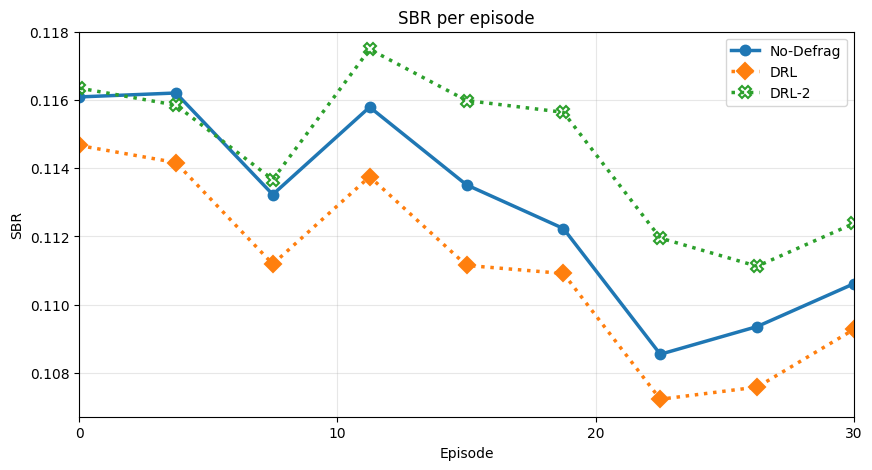

In [28]:
plot_sbr_curves_smoothed(
    res1, 
    methods=("no_defrag", "of_rc2", "of_ff2", "drl", "drl2"), 
    window=22, 
    p_rc=8, 
    n_rc=4, 
    
    p_rc2=5, 
    n_rc2=10,

    p_ff=8, 
    n_ff=4,  
    
    p_ff2=5, 
    n_ff2=10
    )

[warn] Missing key: drl2_defrag_cycles


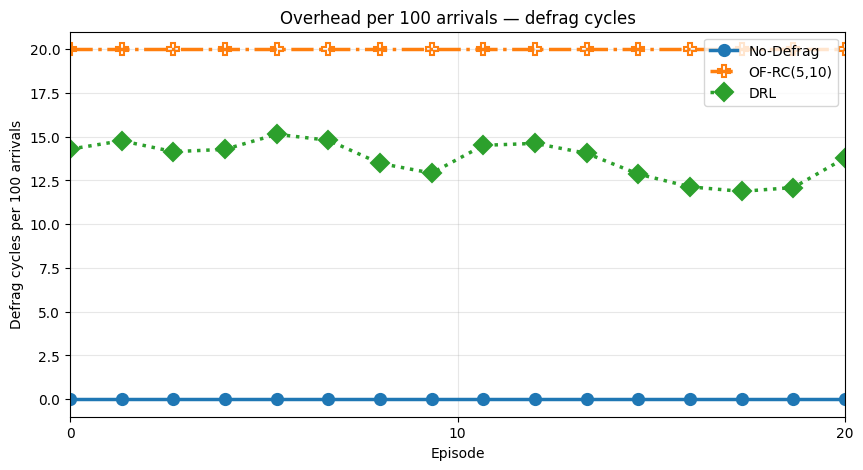

[warn] Missing key: drl2_reallocations


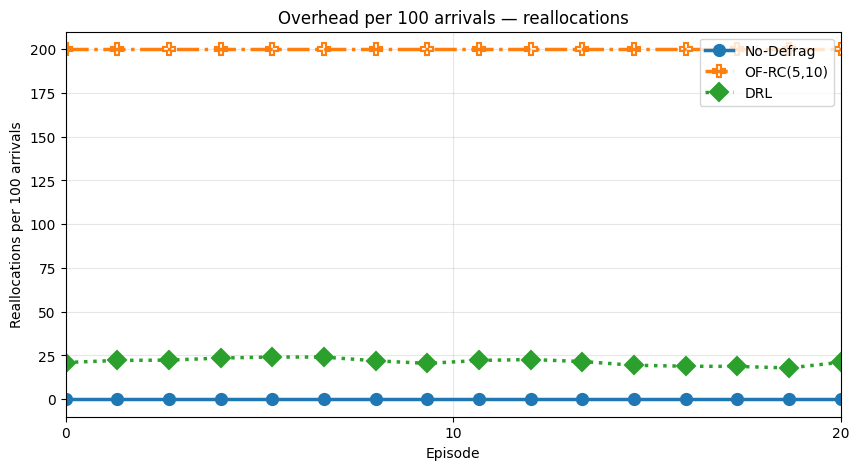

In [20]:
plot_overhead_per_100_arrivals(
    results=res1,
    methods=("no_defrag", "of_rc2", "drl", "drl2"),
    
    of_rc_p=8,
    of_rc_n=4,
    
    of_rc2_p=5,
    of_rc2_n=10,
    
    of_ff_p=8,
    of_ff_n=4,

    of_ff2_p=5,
    of_ff2_n=10,
    
    smooth_window=5,
)

In [3]:
res1 = {'no_defrag_sbr': array([0.03333333, 0.09756098, 0.14285714, 0.03448276, 0.15555556, 0.04545455, 0.03333333, 0.1       , 0.03333333, 0.12820513, 0.11111111,
       0.12820513, 0.08571429, 0.10344828, 0.09302326, 0.05882353, 0.125     , 0.11111111, 0.1       , 0.0952381 , 0.04545455, 0.13888889,
       0.07692308, 0.03448276, 0.03703704, 0.11428571, 0.07142857, 0.13793103, 0.02857143, 0.06122449, 0.08571429, 0.06666667, 0.11111111,
       0.05882353, 0.09090909, 0.1372549 , 0.16666667, 0.08823529, 0.08108108, 0.08333333, 0.06666667, 0.13043478, 0.05263158, 0.04545455,
       0.11363636, 0.06896552, 0.12903226, 0.11627907, 0.13793103, 0.14705882, 0.18181818, 0.09302326, 0.03333333, 0.16666667, 0.        ,
       0.12820513, 0.09615385, 0.11538462, 0.2       , 0.09302326, 0.08823529, 0.075     , 0.15384615, 0.15625   , 0.06451613, 0.11764706,
       0.        , 0.04761905, 0.10344828, 0.06451613, 0.14583333, 0.02777778, 0.16216216, 0.02777778, 0.16216216, 0.08571429, 0.09677419,
       0.10810811, 0.11428571, 0.05555556, 0.05      , 0.14634146, 0.09677419, 0.07692308, 0.11764706, 0.07894737, 0.09302326, 0.05714286,
       0.08823529, 0.08510638, 0.13636364, 0.08108108, 0.0952381 , 0.04761905, 0.09302326, 0.12820513, 0.09090909, 0.03030303, 0.09677419,
       0.10526316]), 'no_defrag_scheduler_sbr': array([0.03333333, 0.09756098, 0.14285714, 0.03448276, 0.15555556, 0.04545455, 0.03333333, 0.1       , 0.03333333, 0.12820513, 0.11111111,
       0.12820513, 0.08571429, 0.10344828, 0.09302326, 0.05882353, 0.125     , 0.11111111, 0.1       , 0.0952381 , 0.04545455, 0.13888889,
       0.07692308, 0.03448276, 0.03703704, 0.11428571, 0.07142857, 0.13793103, 0.02857143, 0.06122449, 0.08571429, 0.06666667, 0.11111111,
       0.05882353, 0.09090909, 0.1372549 , 0.16666667, 0.08823529, 0.08108108, 0.08333333, 0.06666667, 0.13043478, 0.05263158, 0.04545455,
       0.11363636, 0.06896552, 0.12903226, 0.11627907, 0.13793103, 0.14705882, 0.18181818, 0.09302326, 0.03333333, 0.16666667, 0.        ,
       0.12820513, 0.09615385, 0.11538462, 0.2       , 0.09302326, 0.08823529, 0.075     , 0.15384615, 0.15625   , 0.06451613, 0.11764706,
       0.        , 0.04761905, 0.10344828, 0.06451613, 0.14583333, 0.02777778, 0.16216216, 0.02777778, 0.16216216, 0.08571429, 0.09677419,
       0.10810811, 0.11428571, 0.05555556, 0.05      , 0.14634146, 0.09677419, 0.07692308, 0.11764706, 0.07894737, 0.09302326, 0.05714286,
       0.08823529, 0.08510638, 0.13636364, 0.08108108, 0.0952381 , 0.04761905, 0.09302326, 0.12820513, 0.09090909, 0.03030303, 0.09677419,
       0.10526316]), 'no_defrag_acc': array([0.96666667, 0.90243902, 0.85714286, 0.96551724, 0.84444444, 0.95454545, 0.96666667, 0.9       , 0.96666667, 0.87179487, 0.88888889,
       0.87179487, 0.91428571, 0.89655172, 0.90697674, 0.94117647, 0.875     , 0.88888889, 0.9       , 0.9047619 , 0.95454545, 0.86111111,
       0.92307692, 0.96551724, 0.96296296, 0.88571429, 0.92857143, 0.86206897, 0.97142857, 0.93877551, 0.91428571, 0.93333333, 0.88888889,
       0.94117647, 0.90909091, 0.8627451 , 0.83333333, 0.91176471, 0.91891892, 0.91666667, 0.93333333, 0.86956522, 0.94736842, 0.95454545,
       0.88636364, 0.93103448, 0.87096774, 0.88372093, 0.86206897, 0.85294118, 0.81818182, 0.90697674, 0.96666667, 0.83333333, 1.        ,
       0.87179487, 0.90384615, 0.88461538, 0.8       , 0.90697674, 0.91176471, 0.925     , 0.84615385, 0.84375   , 0.93548387, 0.88235294,
       1.        , 0.95238095, 0.89655172, 0.93548387, 0.85416667, 0.97222222, 0.83783784, 0.97222222, 0.83783784, 0.91428571, 0.90322581,
       0.89189189, 0.88571429, 0.94444444, 0.95      , 0.85365854, 0.90322581, 0.92307692, 0.88235294, 0.92105263, 0.90697674, 0.94285714,
       0.91176471, 0.91489362, 0.86363636, 0.91891892, 0.9047619 , 0.95238095, 0.90697674, 0.87179487, 0.90909091, 0.96969697, 0.90322581,
       0.89473684]), 'no_defrag_arrivals': array([30, 41, 35, 29, 45, 22, 30, 40, 30, 39, 36, 39, 35, 29, 43, 34, 48, 27, 30, 42, 22, 36, 26, 29, 27, 35, 28, 29, 35, 49, 35, 30, 36,
       34, 33, 51, 30, 34, 37, 36, 30, 23, 38, 22, 44, 29, 31, 43, 29, 34, 44, 43, 30, 36, 33, 39, 52, 26, 35, 43, 34, 40, 26, 32, 31, 34,
       30, 21, 29, 31, 48, 36, 37, 36, 37, 35, 31, 37, 35, 36, 40, 41, 31, 26, 34, 38, 43, 35, 34, 47, 44, 37, 21, 21, 43, 39, 22, 33, 31,
       38]), 'no_defrag_departures': array([43, 50, 44, 43, 52, 36, 43, 51, 43, 49, 46, 49, 47, 40, 53, 47, 56, 38, 42, 53, 36, 46, 39, 43, 40, 46, 41, 40, 49, 60, 47, 42, 47,
       46, 44, 59, 40, 45, 48, 48, 43, 34, 50, 36, 54, 41, 42, 53, 39, 43, 50, 54, 44, 45, 48, 49, 61, 37, 42, 54, 46, 52, 37, 42, 44, 44,
       45, 35, 41, 44, 56, 50, 46, 49, 46, 47, 42, 48, 45, 49, 52, 50, 43, 39, 45, 50, 54, 48, 46, 58, 53, 49, 34, 35, 53, 49, 35, 47, 43,
       48]), 'no_defrag_scheduler_rejected': array([1, 4, 5, 1, 7, 1, 1, 4, 1, 5, 4, 5, 3, 3, 4, 2, 6, 3, 3, 4, 1, 5, 2, 1, 1, 4, 2, 4, 1, 3, 3, 2, 4, 2, 3, 7, 5, 3, 3, 3, 2, 3, 2, 1,
       5, 2, 4, 5, 4, 5, 8, 4, 1, 6, 0, 5, 5, 3, 7, 4, 3, 3, 4, 5, 2, 4, 0, 1, 3, 2, 7, 1, 6, 1, 6, 3, 3, 4, 4, 2, 2, 6, 3, 2, 4, 3, 4, 2,
       3, 4, 6, 3, 2, 1, 4, 5, 2, 1, 3, 4]), 'no_defrag_decisions': [{1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'scheduler_reject', 8: 'accept', 9: 'accept', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept', 41: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'scheduler_reject', 6: 'scheduler_reject', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'scheduler_reject', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'scheduler_reject', 9: 'accept', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'scheduler_reject', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept', 41: 'accept', 42: 'accept', 43: 'accept', 44: 'accept', 45: 'scheduler_reject'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'scheduler_reject', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'scheduler_reject', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'scheduler_reject', 6: 'scheduler_reject', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'scheduler_reject', 6: 'scheduler_reject', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'scheduler_reject', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'scheduler_reject', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'scheduler_reject', 35: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept'}, {1: 'accept', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'scheduler_reject', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'scheduler_reject', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept', 41: 'accept', 42: 'accept', 43: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'scheduler_reject', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept'}, {1: 'accept', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'scheduler_reject', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'scheduler_reject', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'scheduler_reject', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept', 41: 'accept', 42: 'accept', 43: 'accept', 44: 'accept', 45: 'accept', 46: 'accept', 47: 'accept', 48: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'scheduler_reject', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'scheduler_reject', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept', 41: 'accept', 42: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'scheduler_reject', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept'}, {1: 'accept', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'scheduler_reject', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'scheduler_reject', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept'}, {1: 'accept', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'scheduler_reject', 8: 'accept', 9: 'accept', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'scheduler_reject', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'scheduler_reject', 7: 'scheduler_reject', 8: 'accept', 9: 'accept', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'scheduler_reject'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept'}, {1: 'accept', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept', 41: 'accept', 42: 'accept', 43: 'accept', 44: 'accept', 45: 'accept', 46: 'accept', 47: 'accept', 48: 'accept', 49: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'scheduler_reject', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'scheduler_reject', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'scheduler_reject', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'scheduler_reject', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept', 41: 'accept', 42: 'accept', 43: 'accept', 44: 'accept', 45: 'accept', 46: 'accept', 47: 'accept', 48: 'accept', 49: 'scheduler_reject', 50: 'accept', 51: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'scheduler_reject', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'scheduler_reject', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'scheduler_reject', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'scheduler_reject', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'scheduler_reject', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'scheduler_reject', 7: 'accept', 8: 'scheduler_reject', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'scheduler_reject', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept', 41: 'accept', 42: 'accept', 43: 'accept', 44: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'scheduler_reject', 6: 'scheduler_reject', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'scheduler_reject', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'scheduler_reject', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept', 41: 'accept', 42: 'accept', 43: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'scheduler_reject'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'scheduler_reject', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'scheduler_reject', 8: 'scheduler_reject', 9: 'accept', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'scheduler_reject', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'scheduler_reject', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept', 41: 'accept', 42: 'scheduler_reject', 43: 'accept', 44: 'accept'}, {1: 'accept', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'scheduler_reject', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept', 41: 'accept', 42: 'accept', 43: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'scheduler_reject', 8: 'scheduler_reject', 9: 'scheduler_reject', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'scheduler_reject', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'scheduler_reject', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'scheduler_reject', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'scheduler_reject', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept', 41: 'accept', 42: 'accept', 43: 'accept', 44: 'accept', 45: 'accept', 46: 'accept', 47: 'accept', 48: 'accept', 49: 'accept', 50: 'accept', 51: 'accept', 52: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'scheduler_reject', 8: 'scheduler_reject', 9: 'scheduler_reject', 10: 'scheduler_reject', 11: 'scheduler_reject', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept'}, {1: 'accept', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'scheduler_reject', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'scheduler_reject', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'scheduler_reject', 40: 'accept', 41: 'accept', 42: 'accept', 43: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'scheduler_reject', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'scheduler_reject', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'scheduler_reject', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'scheduler_reject', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'scheduler_reject', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'scheduler_reject', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'scheduler_reject', 30: 'accept', 31: 'accept', 32: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'scheduler_reject', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'scheduler_reject', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'scheduler_reject', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'scheduler_reject', 7: 'accept', 8: 'scheduler_reject', 9: 'scheduler_reject', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept', 41: 'accept', 42: 'accept', 43: 'accept', 44: 'accept', 45: 'accept', 46: 'accept', 47: 'accept', 48: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'scheduler_reject', 6: 'scheduler_reject', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'scheduler_reject', 35: 'accept', 36: 'accept', 37: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'scheduler_reject', 7: 'accept', 8: 'scheduler_reject', 9: 'accept', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'scheduler_reject', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'scheduler_reject', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'scheduler_reject', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept'}, {1: 'accept', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'accept', 6: 'scheduler_reject', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'scheduler_reject', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'scheduler_reject', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'scheduler_reject', 17: 'accept', 18: 'accept', 19: 'scheduler_reject', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'scheduler_reject', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'scheduler_reject', 40: 'scheduler_reject', 41: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'scheduler_reject', 9: 'accept', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'scheduler_reject', 6: 'scheduler_reject', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'scheduler_reject', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'scheduler_reject', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'scheduler_reject', 40: 'accept', 41: 'accept', 42: 'accept', 43: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'scheduler_reject', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'scheduler_reject', 6: 'scheduler_reject', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept', 41: 'accept', 42: 'accept', 43: 'accept', 44: 'accept', 45: 'accept', 46: 'accept', 47: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'scheduler_reject', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'scheduler_reject', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept', 41: 'accept', 42: 'accept', 43: 'accept', 44: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'scheduler_reject', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept', 41: 'accept', 42: 'accept', 43: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'scheduler_reject', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'scheduler_reject'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'scheduler_reject', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'scheduler_reject', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'scheduler_reject', 8: 'scheduler_reject', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept'}], 'no_defrag_reallocations': array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]), 'no_defrag_defrag_cycles': array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]), 'no_defrag_successful_defrag_cycles': array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]), 'no_defrag_failed_defrag_cycles': array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]), 'no_defrag_trace_steps': array([100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100,
       100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100,
       100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100,
       100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100]), 'no_defrag_departure_attempts': array([100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100,
       100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100,
       100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100,
       100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100]), 'no_defrag_requested_departures': array([100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100,
       100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100,
       100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100,
       100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100]), 'no_defrag_executed_departures': array([43, 50, 44, 43, 52, 36, 43, 51, 43, 49, 46, 49, 47, 40, 53, 47, 56, 38, 42, 53, 36, 46, 39, 43, 40, 46, 41, 40, 49, 60, 47, 42, 47,
       46, 44, 59, 40, 45, 48, 48, 43, 34, 50, 36, 54, 41, 42, 53, 39, 43, 50, 54, 44, 45, 48, 49, 61, 37, 42, 54, 46, 52, 37, 42, 44, 44,
       45, 35, 41, 44, 56, 50, 46, 49, 46, 47, 42, 48, 45, 49, 52, 50, 43, 39, 45, 50, 54, 48, 46, 58, 53, 49, 34, 35, 53, 49, 35, 47, 43,
       48]), 'no_defrag_skipped_departures': array([57, 50, 56, 57, 48, 64, 57, 49, 57, 51, 54, 51, 53, 60, 47, 53, 44, 62, 58, 47, 64, 54, 61, 57, 60, 54, 59, 60, 51, 40, 53, 58, 53,
       54, 56, 41, 60, 55, 52, 52, 57, 66, 50, 64, 46, 59, 58, 47, 61, 57, 50, 46, 56, 55, 52, 51, 39, 63, 58, 46, 54, 48, 63, 58, 56, 56,
       55, 65, 59, 56, 44, 50, 54, 51, 54, 53, 58, 52, 55, 51, 48, 50, 57, 61, 55, 50, 46, 52, 54, 42, 47, 51, 66, 65, 47, 51, 65, 53, 57,
       52]), 'of_rc_sbr': array([0.03333333, 0.09756098, 0.11428571, 0.03448276, 0.15555556, 0.04545455, 0.        , 0.1       , 0.        , 0.05128205, 0.11111111,
       0.1025641 , 0.05714286, 0.06896552, 0.11627907, 0.05882353, 0.08333333, 0.11111111, 0.03333333, 0.07142857, 0.04545455, 0.13888889,
       0.03846154, 0.03448276, 0.        , 0.11428571, 0.07142857, 0.13793103, 0.02857143, 0.04081633, 0.05714286, 0.06666667, 0.11111111,
       0.05882353, 0.06060606, 0.11764706, 0.1       , 0.05882353, 0.08108108, 0.05555556, 0.03333333, 0.08695652, 0.05263158, 0.04545455,
       0.15909091, 0.03448276, 0.09677419, 0.09302326, 0.10344828, 0.11764706, 0.18181818, 0.09302326, 0.03333333, 0.16666667, 0.        ,
       0.1025641 , 0.13461538, 0.07692308, 0.14285714, 0.06976744, 0.02941176, 0.075     , 0.11538462, 0.125     , 0.06451613, 0.11764706,
       0.        , 0.04761905, 0.10344828, 0.03225806, 0.125     , 0.02777778, 0.16216216, 0.02777778, 0.13513514, 0.08571429, 0.06451613,
       0.02702703, 0.05714286, 0.02777778, 0.075     , 0.14634146, 0.09677419, 0.07692308, 0.05882353, 0.05263158, 0.06976744, 0.05714286,
       0.05882353, 0.06382979, 0.09090909, 0.08108108, 0.0952381 , 0.04761905, 0.11627907, 0.12820513, 0.09090909, 0.03030303, 0.09677419,
       0.10526316]), 'of_rc_scheduler_sbr': array([0.03333333, 0.09756098, 0.11428571, 0.03448276, 0.15555556, 0.04545455, 0.        , 0.1       , 0.        , 0.05128205, 0.11111111,
       0.1025641 , 0.05714286, 0.06896552, 0.11627907, 0.05882353, 0.08333333, 0.11111111, 0.03333333, 0.07142857, 0.04545455, 0.13888889,
       0.03846154, 0.03448276, 0.        , 0.11428571, 0.07142857, 0.13793103, 0.02857143, 0.04081633, 0.05714286, 0.06666667, 0.11111111,
       0.05882353, 0.06060606, 0.11764706, 0.1       , 0.05882353, 0.08108108, 0.05555556, 0.03333333, 0.08695652, 0.05263158, 0.04545455,
       0.15909091, 0.03448276, 0.09677419, 0.09302326, 0.10344828, 0.11764706, 0.18181818, 0.09302326, 0.03333333, 0.16666667, 0.        ,
       0.1025641 , 0.13461538, 0.07692308, 0.14285714, 0.06976744, 0.02941176, 0.075     , 0.11538462, 0.125     , 0.06451613, 0.11764706,
       0.        , 0.04761905, 0.10344828, 0.03225806, 0.125     , 0.02777778, 0.16216216, 0.02777778, 0.13513514, 0.08571429, 0.06451613,
       0.02702703, 0.05714286, 0.02777778, 0.075     , 0.14634146, 0.09677419, 0.07692308, 0.05882353, 0.05263158, 0.06976744, 0.05714286,
       0.05882353, 0.06382979, 0.09090909, 0.08108108, 0.0952381 , 0.04761905, 0.11627907, 0.12820513, 0.09090909, 0.03030303, 0.09677419,
       0.10526316]), 'of_rc_acc': array([0.96666667, 0.90243902, 0.88571429, 0.96551724, 0.84444444, 0.95454545, 1.        , 0.9       , 1.        , 0.94871795, 0.88888889,
       0.8974359 , 0.94285714, 0.93103448, 0.88372093, 0.94117647, 0.91666667, 0.88888889, 0.96666667, 0.92857143, 0.95454545, 0.86111111,
       0.96153846, 0.96551724, 1.        , 0.88571429, 0.92857143, 0.86206897, 0.97142857, 0.95918367, 0.94285714, 0.93333333, 0.88888889,
       0.94117647, 0.93939394, 0.88235294, 0.9       , 0.94117647, 0.91891892, 0.94444444, 0.96666667, 0.91304348, 0.94736842, 0.95454545,
       0.84090909, 0.96551724, 0.90322581, 0.90697674, 0.89655172, 0.88235294, 0.81818182, 0.90697674, 0.96666667, 0.83333333, 1.        ,
       0.8974359 , 0.86538462, 0.92307692, 0.85714286, 0.93023256, 0.97058824, 0.925     , 0.88461538, 0.875     , 0.93548387, 0.88235294,
       1.        , 0.95238095, 0.89655172, 0.96774194, 0.875     , 0.97222222, 0.83783784, 0.97222222, 0.86486486, 0.91428571, 0.93548387,
       0.97297297, 0.94285714, 0.97222222, 0.925     , 0.85365854, 0.90322581, 0.92307692, 0.94117647, 0.94736842, 0.93023256, 0.94285714,
       0.94117647, 0.93617021, 0.90909091, 0.91891892, 0.9047619 , 0.95238095, 0.88372093, 0.87179487, 0.90909091, 0.96969697, 0.90322581,
       0.89473684]), 'of_rc_arrivals': array([30, 41, 35, 29, 45, 22, 30, 40, 30, 39, 36, 39, 35, 29, 43, 34, 48, 27, 30, 42, 22, 36, 26, 29, 27, 35, 28, 29, 35, 49, 35, 30, 36,
       34, 33, 51, 30, 34, 37, 36, 30, 23, 38, 22, 44, 29, 31, 43, 29, 34, 44, 43, 30, 36, 33, 39, 52, 26, 35, 43, 34, 40, 26, 32, 31, 34,
       30, 21, 29, 31, 48, 36, 37, 36, 37, 35, 31, 37, 35, 36, 40, 41, 31, 26, 34, 38, 43, 35, 34, 47, 44, 37, 21, 21, 43, 39, 22, 33, 31,
       38]), 'of_rc_departures': array([43, 50, 45, 43, 52, 36, 44, 51, 44, 52, 46, 50, 48, 41, 52, 47, 58, 38, 44, 54, 36, 46, 40, 43, 41, 46, 41, 40, 49, 61, 48, 42, 47,
       46, 45, 60, 42, 46, 48, 49, 44, 35, 50, 36, 52, 42, 43, 54, 40, 44, 50, 54, 44, 45, 48, 50, 59, 38, 44, 55, 48, 52, 38, 43, 44, 44,
       45, 35, 41, 45, 57, 50, 46, 49, 47, 47, 43, 51, 47, 50, 51, 50, 43, 39, 47, 51, 55, 48, 47, 59, 55, 49, 34, 35, 52, 49, 35, 47, 43,
       48]), 'of_rc_scheduler_rejected': array([1, 4, 4, 1, 7, 1, 0, 4, 0, 2, 4, 4, 2, 2, 5, 2, 4, 3, 1, 3, 1, 5, 1, 1, 0, 4, 2, 4, 1, 2, 2, 2, 4, 2, 2, 6, 3, 2, 3, 2, 1, 2, 2, 1,
       7, 1, 3, 4, 3, 4, 8, 4, 1, 6, 0, 4, 7, 2, 5, 3, 1, 3, 3, 4, 2, 4, 0, 1, 3, 1, 6, 1, 6, 1, 5, 3, 2, 1, 2, 1, 3, 6, 3, 2, 2, 2, 3, 2,
       2, 3, 4, 3, 2, 1, 5, 5, 2, 1, 3, 4]), 'of_rc_decisions': [{1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'scheduler_reject', 8: 'accept', 9: 'accept', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept', 41: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'scheduler_reject', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'scheduler_reject', 9: 'accept', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'scheduler_reject', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept', 41: 'accept', 42: 'accept', 43: 'accept', 44: 'accept', 45: 'scheduler_reject'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'scheduler_reject', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'scheduler_reject', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'scheduler_reject', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'scheduler_reject', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'scheduler_reject', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'scheduler_reject', 8: 'scheduler_reject', 9: 'accept', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'scheduler_reject', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept', 41: 'accept', 42: 'accept', 43: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'scheduler_reject', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'scheduler_reject', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'scheduler_reject', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept', 41: 'accept', 42: 'accept', 43: 'accept', 44: 'accept', 45: 'accept', 46: 'accept', 47: 'accept', 48: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'scheduler_reject', 7: 'scheduler_reject', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept', 41: 'accept', 42: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'scheduler_reject', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'scheduler_reject', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'scheduler_reject', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'scheduler_reject', 8: 'accept', 9: 'accept', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'scheduler_reject', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'scheduler_reject', 7: 'scheduler_reject', 8: 'accept', 9: 'accept', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'scheduler_reject'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept', 41: 'accept', 42: 'accept', 43: 'accept', 44: 'accept', 45: 'accept', 46: 'accept', 47: 'accept', 48: 'accept', 49: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'scheduler_reject', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'scheduler_reject', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'scheduler_reject', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'scheduler_reject', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'scheduler_reject', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept', 41: 'accept', 42: 'accept', 43: 'accept', 44: 'accept', 45: 'accept', 46: 'accept', 47: 'accept', 48: 'accept', 49: 'scheduler_reject', 50: 'accept', 51: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'scheduler_reject', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'scheduler_reject', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'scheduler_reject', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'scheduler_reject', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'scheduler_reject', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'scheduler_reject', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'scheduler_reject', 9: 'accept', 10: 'accept', 11: 'scheduler_reject', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'scheduler_reject', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'scheduler_reject', 40: 'accept', 41: 'accept', 42: 'accept', 43: 'accept', 44: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'scheduler_reject', 7: 'scheduler_reject', 8: 'scheduler_reject', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'scheduler_reject', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept', 41: 'accept', 42: 'accept', 43: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'scheduler_reject'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'scheduler_reject', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'scheduler_reject', 8: 'scheduler_reject', 9: 'accept', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'scheduler_reject', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'scheduler_reject', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept', 41: 'accept', 42: 'scheduler_reject', 43: 'accept', 44: 'accept'}, {1: 'accept', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'scheduler_reject', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept', 41: 'accept', 42: 'accept', 43: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'scheduler_reject', 8: 'scheduler_reject', 9: 'scheduler_reject', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'scheduler_reject', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'scheduler_reject', 8: 'accept', 9: 'accept', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'scheduler_reject', 25: 'scheduler_reject', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'scheduler_reject', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept', 41: 'accept', 42: 'accept', 43: 'accept', 44: 'accept', 45: 'accept', 46: 'accept', 47: 'accept', 48: 'accept', 49: 'accept', 50: 'accept', 51: 'accept', 52: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'scheduler_reject', 8: 'scheduler_reject', 9: 'accept', 10: 'scheduler_reject', 11: 'accept', 12: 'scheduler_reject', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'scheduler_reject', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'scheduler_reject', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'scheduler_reject', 40: 'accept', 41: 'accept', 42: 'accept', 43: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'scheduler_reject', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'scheduler_reject', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'scheduler_reject', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'scheduler_reject', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'scheduler_reject', 30: 'accept', 31: 'accept', 32: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'scheduler_reject', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'scheduler_reject', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'scheduler_reject', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'scheduler_reject', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'scheduler_reject', 8: 'scheduler_reject', 9: 'scheduler_reject', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept', 41: 'accept', 42: 'accept', 43: 'accept', 44: 'accept', 45: 'accept', 46: 'accept', 47: 'accept', 48: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'scheduler_reject', 9: 'accept', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'scheduler_reject', 35: 'accept', 36: 'accept', 37: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'scheduler_reject', 8: 'scheduler_reject', 9: 'accept', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'scheduler_reject', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'scheduler_reject', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'scheduler_reject', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'scheduler_reject', 17: 'accept', 18: 'accept', 19: 'scheduler_reject', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'scheduler_reject', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'scheduler_reject', 40: 'scheduler_reject', 41: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'scheduler_reject', 9: 'accept', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'scheduler_reject', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'scheduler_reject', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'scheduler_reject', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'scheduler_reject', 40: 'accept', 41: 'accept', 42: 'accept', 43: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'scheduler_reject', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept', 41: 'accept', 42: 'accept', 43: 'accept', 44: 'accept', 45: 'accept', 46: 'accept', 47: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'scheduler_reject', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'scheduler_reject', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept', 41: 'accept', 42: 'accept', 43: 'accept', 44: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'scheduler_reject', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'scheduler_reject', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept', 41: 'accept', 42: 'accept', 43: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'scheduler_reject', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'scheduler_reject', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'scheduler_reject'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'scheduler_reject', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'scheduler_reject', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'scheduler_reject', 8: 'scheduler_reject', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept'}], 'of_rc_reallocations': array([15, 12, 15, 17, 15, 13, 18, 16, 14, 18, 14, 11, 15, 18, 11, 18, 17, 10, 13, 21, 16, 13, 15, 19, 13, 19, 16, 19, 11, 17, 16, 10, 15,
       15, 17, 16, 18, 11,  3, 11, 12, 12, 21, 12, 10, 13, 11, 11,  7, 13, 15, 21, 13, 10, 18, 15, 17, 16, 12, 13, 22, 12, 14, 12, 13, 13,
       17, 14, 16, 13, 22,  4, 17, 14, 10, 12, 17, 20, 13, 12, 16, 17, 12, 14, 12, 17, 11, 18, 13, 15, 10, 10, 17, 16, 14, 14, 13, 20, 14,
       14]), 'of_rc_defrag_cycles': array([ 8, 10,  9,  8, 10,  7,  8, 10,  8, 10,  9, 10,  9,  8, 10,  9, 11,  7,  8, 10,  7,  9,  8,  8,  8,  9,  8,  8,  9, 12,  9,  8,  9,
        9,  9, 12,  8,  9,  9,  9,  8,  7, 10,  7, 10,  8,  8, 10,  8,  8, 10, 10,  8,  9,  9, 10, 11,  7,  8, 11,  9, 10,  7,  8,  8,  8,
        9,  7,  8,  9, 11, 10,  9,  9,  9,  9,  8, 10,  9, 10, 10, 10,  8,  7,  9, 10, 11,  9,  9, 11, 11,  9,  6,  7, 10,  9,  7,  9,  8,
        9]), 'of_rc_successful_defrag_cycles': array([ 8,  8,  8,  7,  9,  6,  8,  9,  8,  9,  8,  8,  8,  7,  8,  8,  9,  5,  6, 10,  7,  7,  7,  8,  7,  9,  8,  7,  8, 10,  8,  6,  8,
        8,  8, 12,  8,  7,  7,  7,  7,  6, 10,  6,  7,  7,  6,  8,  7,  6,  9, 10,  7,  7,  9,  9,  9,  6,  5,  9,  9,  8,  6,  6,  8,  7,
        8,  6,  8,  8, 11,  8,  7,  9,  7,  7,  8, 10,  7,  8,  9, 10,  7,  7,  7, 10,  9,  9,  8, 10,  9,  7,  6,  7,  9,  8,  7,  9,  7,
        8]), 'of_rc_failed_defrag_cycles': array([0, 2, 1, 1, 1, 1, 0, 1, 0, 1, 1, 2, 1, 1, 2, 1, 2, 2, 2, 0, 0, 2, 1, 0, 1, 0, 0, 1, 1, 2, 1, 2, 1, 1, 1, 0, 0, 2, 2, 2, 1, 1, 0, 1,
       3, 1, 2, 2, 1, 2, 1, 0, 1, 2, 0, 1, 2, 1, 3, 2, 0, 2, 1, 2, 0, 1, 1, 1, 0, 1, 0, 2, 2, 0, 2, 2, 0, 0, 2, 2, 1, 0, 1, 0, 2, 0, 2, 0,
       1, 1, 2, 2, 0, 0, 1, 1, 0, 0, 1, 1]), 'of_rc_trace_steps': array([100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100,
       100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100,
       100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100,
       100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100]), 'of_rc_departure_attempts': array([100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100,
       100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100,
       100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100,
       100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100]), 'of_rc_requested_departures': array([100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100,
       100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100,
       100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100,
       100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100]), 'of_rc_executed_departures': array([43, 50, 45, 43, 52, 36, 44, 51, 44, 52, 46, 50, 48, 41, 52, 47, 58, 38, 44, 54, 36, 46, 40, 43, 41, 46, 41, 40, 49, 61, 48, 42, 47,
       46, 45, 60, 42, 46, 48, 49, 44, 35, 50, 36, 52, 42, 43, 54, 40, 44, 50, 54, 44, 45, 48, 50, 59, 38, 44, 55, 48, 52, 38, 43, 44, 44,
       45, 35, 41, 45, 57, 50, 46, 49, 47, 47, 43, 51, 47, 50, 51, 50, 43, 39, 47, 51, 55, 48, 47, 59, 55, 49, 34, 35, 52, 49, 35, 47, 43,
       48]), 'of_rc_skipped_departures': array([57, 50, 55, 57, 48, 64, 56, 49, 56, 48, 54, 50, 52, 59, 48, 53, 42, 62, 56, 46, 64, 54, 60, 57, 59, 54, 59, 60, 51, 39, 52, 58, 53,
       54, 55, 40, 58, 54, 52, 51, 56, 65, 50, 64, 48, 58, 57, 46, 60, 56, 50, 46, 56, 55, 52, 50, 41, 62, 56, 45, 52, 48, 62, 57, 56, 56,
       55, 65, 59, 55, 43, 50, 54, 51, 53, 53, 57, 49, 53, 50, 49, 50, 57, 61, 53, 49, 45, 52, 53, 41, 45, 51, 66, 65, 48, 51, 65, 53, 57,
       52]), 'of_rc_gain': array([0, 0, 3, 0, 0, 0, 1, 1, 1, 4, 1, 1, 1, 1, 1, 0, 2, 0, 2, 2, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 2, 2, 1, 0, 1, 1, 1, 1, 0,
       1, 1, 1, 3, 1, 2, 1, 0, 0, 0, 0, 1, 3, 1, 3, 1, 2, 0, 1, 2, 0, 1, 0, 0, 1, 1, 2, 0, 2, 0, 2, 0, 1, 3, 3, 1, 0, 0, 0, 0, 3, 1, 1, 0,
       1, 1, 2, 0, 0, 0, 0, 1, 0, 0, 0, 1]), 'of_rc_damage': array([0, 0, 2, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 2, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0,
       3, 0, 0, 2, 0, 1, 1, 0, 0, 0, 0, 0, 5, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 2, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1]), 'of_rc_net_gain': array([ 0,  0,  1,  0,  0,  0,  1,  0,  1,  3,  0,  1,  1,  1, -1,  0,  2,  0,  2,  1,  0,  0,  1,  0,  1,  0,  0,  0,  0,  1,  1,  0,  0,
        0,  1,  1,  2,  1,  0,  1,  1,  1,  0,  0, -2,  1,  1,  1,  1,  1,  0,  0,  0,  0,  0,  1, -2,  1,  2,  1,  2,  0,  1,  1,  0,  0,
        0,  0,  0,  1,  1,  0,  0,  0,  1,  0,  1,  3,  2,  1, -1,  0,  0,  0,  2,  1,  1,  0,  1,  1,  2,  0,  0,  0, -1,  0,  0,  0,  0,
        0]), 'drl_sbr': array([0.03333333, 0.09756098, 0.17142857, 0.03448276, 0.11111111, 0.04545455, 0.03333333, 0.1       , 0.03333333, 0.05128205, 0.02777778,
       0.1025641 , 0.08571429, 0.10344828, 0.13953488, 0.05882353, 0.08333333, 0.11111111, 0.03333333, 0.07142857, 0.09090909, 0.13888889,
       0.07692308, 0.03448276, 0.03703704, 0.11428571, 0.07142857, 0.17241379, 0.02857143, 0.06122449, 0.05714286, 0.06666667, 0.11111111,
       0.05882353, 0.06060606, 0.1372549 , 0.1       , 0.05882353, 0.08108108, 0.08333333, 0.06666667, 0.08695652, 0.02631579, 0.04545455,
       0.15909091, 0.06896552, 0.06451613, 0.09302326, 0.06896552, 0.14705882, 0.15909091, 0.09302326, 0.03333333, 0.16666667, 0.        ,
       0.12820513, 0.09615385, 0.07692308, 0.2       , 0.09302326, 0.02941176, 0.075     , 0.15384615, 0.125     , 0.06451613, 0.05882353,
       0.03333333, 0.0952381 , 0.10344828, 0.06451613, 0.14583333, 0.05555556, 0.10810811, 0.        , 0.08108108, 0.08571429, 0.06451613,
       0.08108108, 0.05714286, 0.05555556, 0.1       , 0.14634146, 0.06451613, 0.07692308, 0.11764706, 0.07894737, 0.09302326, 0.05714286,
       0.05882353, 0.06382979, 0.09090909, 0.08108108, 0.0952381 , 0.04761905, 0.09302326, 0.12820513, 0.04545455, 0.03030303, 0.12903226,
       0.10526316]), 'drl_scheduler_sbr': array([0.03333333, 0.09756098, 0.17142857, 0.03448276, 0.11111111, 0.04545455, 0.03333333, 0.1       , 0.03333333, 0.05128205, 0.02777778,
       0.1025641 , 0.08571429, 0.10344828, 0.13953488, 0.05882353, 0.08333333, 0.11111111, 0.03333333, 0.07142857, 0.09090909, 0.13888889,
       0.07692308, 0.03448276, 0.03703704, 0.11428571, 0.07142857, 0.17241379, 0.02857143, 0.06122449, 0.05714286, 0.06666667, 0.11111111,
       0.05882353, 0.06060606, 0.1372549 , 0.1       , 0.05882353, 0.08108108, 0.08333333, 0.06666667, 0.08695652, 0.02631579, 0.04545455,
       0.15909091, 0.06896552, 0.06451613, 0.09302326, 0.06896552, 0.14705882, 0.15909091, 0.09302326, 0.03333333, 0.16666667, 0.        ,
       0.12820513, 0.09615385, 0.07692308, 0.2       , 0.09302326, 0.02941176, 0.075     , 0.15384615, 0.125     , 0.06451613, 0.05882353,
       0.03333333, 0.0952381 , 0.10344828, 0.06451613, 0.14583333, 0.05555556, 0.10810811, 0.        , 0.08108108, 0.08571429, 0.06451613,
       0.08108108, 0.05714286, 0.05555556, 0.1       , 0.14634146, 0.06451613, 0.07692308, 0.11764706, 0.07894737, 0.09302326, 0.05714286,
       0.05882353, 0.06382979, 0.09090909, 0.08108108, 0.0952381 , 0.04761905, 0.09302326, 0.12820513, 0.04545455, 0.03030303, 0.12903226,
       0.10526316]), 'drl_acc': array([0.96666667, 0.90243902, 0.82857143, 0.96551724, 0.88888889, 0.95454545, 0.96666667, 0.9       , 0.96666667, 0.94871795, 0.97222222,
       0.8974359 , 0.91428571, 0.89655172, 0.86046512, 0.94117647, 0.91666667, 0.88888889, 0.96666667, 0.92857143, 0.90909091, 0.86111111,
       0.92307692, 0.96551724, 0.96296296, 0.88571429, 0.92857143, 0.82758621, 0.97142857, 0.93877551, 0.94285714, 0.93333333, 0.88888889,
       0.94117647, 0.93939394, 0.8627451 , 0.9       , 0.94117647, 0.91891892, 0.91666667, 0.93333333, 0.91304348, 0.97368421, 0.95454545,
       0.84090909, 0.93103448, 0.93548387, 0.90697674, 0.93103448, 0.85294118, 0.84090909, 0.90697674, 0.96666667, 0.83333333, 1.        ,
       0.87179487, 0.90384615, 0.92307692, 0.8       , 0.90697674, 0.97058824, 0.925     , 0.84615385, 0.875     , 0.93548387, 0.94117647,
       0.96666667, 0.9047619 , 0.89655172, 0.93548387, 0.85416667, 0.94444444, 0.89189189, 1.        , 0.91891892, 0.91428571, 0.93548387,
       0.91891892, 0.94285714, 0.94444444, 0.9       , 0.85365854, 0.93548387, 0.92307692, 0.88235294, 0.92105263, 0.90697674, 0.94285714,
       0.94117647, 0.93617021, 0.90909091, 0.91891892, 0.9047619 , 0.95238095, 0.90697674, 0.87179487, 0.95454545, 0.96969697, 0.87096774,
       0.89473684]), 'drl_arrivals': array([30, 41, 35, 29, 45, 22, 30, 40, 30, 39, 36, 39, 35, 29, 43, 34, 48, 27, 30, 42, 22, 36, 26, 29, 27, 35, 28, 29, 35, 49, 35, 30, 36,
       34, 33, 51, 30, 34, 37, 36, 30, 23, 38, 22, 44, 29, 31, 43, 29, 34, 44, 43, 30, 36, 33, 39, 52, 26, 35, 43, 34, 40, 26, 32, 31, 34,
       30, 21, 29, 31, 48, 36, 37, 36, 37, 35, 31, 37, 35, 36, 40, 41, 31, 26, 34, 38, 43, 35, 34, 47, 44, 37, 21, 21, 43, 39, 22, 33, 31,
       38]), 'drl_departures': array([43, 50, 43, 43, 54, 36, 43, 51, 43, 52, 49, 50, 47, 40, 51, 47, 58, 38, 44, 54, 35, 46, 39, 43, 40, 46, 41, 39, 49, 60, 48, 42, 47,
       46, 45, 59, 42, 46, 48, 48, 43, 35, 51, 36, 52, 41, 44, 54, 41, 43, 51, 54, 44, 45, 48, 49, 61, 38, 42, 54, 48, 52, 37, 43, 44, 46,
       44, 34, 41, 44, 56, 49, 48, 50, 49, 47, 43, 49, 47, 49, 50, 50, 44, 39, 45, 50, 54, 48, 47, 59, 55, 49, 34, 35, 53, 49, 36, 47, 42,
       48]), 'drl_scheduler_rejected': array([1, 4, 6, 1, 5, 1, 1, 4, 1, 2, 1, 4, 3, 3, 6, 2, 4, 3, 1, 3, 2, 5, 2, 1, 1, 4, 2, 5, 1, 3, 2, 2, 4, 2, 2, 7, 3, 2, 3, 3, 2, 2, 1, 1,
       7, 2, 2, 4, 2, 5, 7, 4, 1, 6, 0, 5, 5, 2, 7, 4, 1, 3, 4, 4, 2, 2, 1, 2, 3, 2, 7, 2, 4, 0, 3, 3, 2, 3, 2, 2, 4, 6, 2, 2, 4, 3, 4, 2,
       2, 3, 4, 3, 2, 1, 4, 5, 1, 1, 4, 4]), 'drl_decisions': [{1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'scheduler_reject', 8: 'accept', 9: 'accept', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept', 41: 'accept'}, {1: 'scheduler_reject', 2: 'scheduler_reject', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'scheduler_reject', 7: 'scheduler_reject', 8: 'scheduler_reject', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'scheduler_reject', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'scheduler_reject', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept', 41: 'accept', 42: 'accept', 43: 'accept', 44: 'accept', 45: 'scheduler_reject'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept'}, {1: 'accept', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'scheduler_reject', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'scheduler_reject', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept'}, {1: 'accept', 2: 'scheduler_reject', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'scheduler_reject', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'scheduler_reject', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'scheduler_reject', 35: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept'}, {1: 'accept', 2: 'accept', 3: 'scheduler_reject', 4: 'scheduler_reject', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'scheduler_reject', 9: 'accept', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'scheduler_reject', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept', 41: 'accept', 42: 'accept', 43: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'scheduler_reject', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'scheduler_reject', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'scheduler_reject', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept', 41: 'accept', 42: 'accept', 43: 'accept', 44: 'accept', 45: 'accept', 46: 'accept', 47: 'accept', 48: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'scheduler_reject', 7: 'scheduler_reject', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept', 41: 'accept', 42: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'scheduler_reject', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept'}, {1: 'accept', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'scheduler_reject', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'scheduler_reject', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'scheduler_reject', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'scheduler_reject', 8: 'accept', 9: 'accept', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'scheduler_reject', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'scheduler_reject', 5: 'accept', 6: 'scheduler_reject', 7: 'scheduler_reject', 8: 'accept', 9: 'accept', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'scheduler_reject'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept', 41: 'accept', 42: 'accept', 43: 'accept', 44: 'accept', 45: 'accept', 46: 'accept', 47: 'accept', 48: 'accept', 49: 'accept'}, {1: 'accept', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'scheduler_reject', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'scheduler_reject', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'scheduler_reject', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'scheduler_reject', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept', 41: 'accept', 42: 'accept', 43: 'accept', 44: 'accept', 45: 'accept', 46: 'accept', 47: 'accept', 48: 'accept', 49: 'scheduler_reject', 50: 'accept', 51: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'scheduler_reject', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'scheduler_reject', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'scheduler_reject', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'scheduler_reject', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'scheduler_reject', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'scheduler_reject', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'scheduler_reject', 9: 'accept', 10: 'accept', 11: 'scheduler_reject', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'scheduler_reject', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'scheduler_reject', 40: 'accept', 41: 'accept', 42: 'accept', 43: 'accept', 44: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'scheduler_reject', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'scheduler_reject', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept', 41: 'accept', 42: 'accept', 43: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'scheduler_reject'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'scheduler_reject', 8: 'accept', 9: 'accept', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'scheduler_reject', 8: 'scheduler_reject', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'scheduler_reject', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'scheduler_reject', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept', 41: 'accept', 42: 'scheduler_reject', 43: 'accept', 44: 'accept'}, {1: 'accept', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'scheduler_reject', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept', 41: 'accept', 42: 'accept', 43: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'scheduler_reject', 8: 'scheduler_reject', 9: 'scheduler_reject', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'scheduler_reject', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept'}, {1: 'accept', 2: 'accept', 3: 'scheduler_reject', 4: 'scheduler_reject', 5: 'accept', 6: 'accept', 7: 'scheduler_reject', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'scheduler_reject', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'scheduler_reject', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'scheduler_reject', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept', 41: 'accept', 42: 'accept', 43: 'accept', 44: 'accept', 45: 'accept', 46: 'accept', 47: 'accept', 48: 'accept', 49: 'accept', 50: 'accept', 51: 'accept', 52: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'scheduler_reject', 5: 'accept', 6: 'accept', 7: 'scheduler_reject', 8: 'scheduler_reject', 9: 'scheduler_reject', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'scheduler_reject', 9: 'accept', 10: 'accept', 11: 'scheduler_reject', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'scheduler_reject', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'scheduler_reject', 40: 'accept', 41: 'accept', 42: 'accept', 43: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'scheduler_reject', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'scheduler_reject', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'scheduler_reject', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'scheduler_reject', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'scheduler_reject', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'scheduler_reject', 30: 'accept', 31: 'accept', 32: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'scheduler_reject', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept'}, {1: 'accept', 2: 'scheduler_reject', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'scheduler_reject', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'scheduler_reject', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept'}, {1: 'scheduler_reject', 2: 'scheduler_reject', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'scheduler_reject', 8: 'scheduler_reject', 9: 'scheduler_reject', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept', 41: 'accept', 42: 'accept', 43: 'accept', 44: 'accept', 45: 'accept', 46: 'accept', 47: 'accept', 48: 'accept'}, {1: 'accept', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'scheduler_reject', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'scheduler_reject', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'scheduler_reject', 8: 'accept', 9: 'accept', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'scheduler_reject', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'scheduler_reject', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'scheduler_reject', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'scheduler_reject', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'scheduler_reject', 9: 'scheduler_reject', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'scheduler_reject', 17: 'accept', 18: 'accept', 19: 'scheduler_reject', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'scheduler_reject', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'scheduler_reject', 40: 'scheduler_reject', 41: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'scheduler_reject', 9: 'accept', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'scheduler_reject', 6: 'scheduler_reject', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'scheduler_reject', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'scheduler_reject', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'scheduler_reject', 40: 'accept', 41: 'accept', 42: 'accept', 43: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'scheduler_reject', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'scheduler_reject', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept', 41: 'accept', 42: 'accept', 43: 'accept', 44: 'accept', 45: 'accept', 46: 'accept', 47: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'scheduler_reject', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'scheduler_reject', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept', 41: 'accept', 42: 'accept', 43: 'accept', 44: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'scheduler_reject', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'scheduler_reject', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'scheduler_reject', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'accept', 40: 'accept', 41: 'accept', 42: 'accept', 43: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'scheduler_reject', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'scheduler_reject', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'scheduler_reject', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept', 39: 'scheduler_reject'}, {1: 'accept', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'scheduler_reject', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'accept', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'scheduler_reject', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'accept', 8: 'scheduler_reject', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'accept', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'scheduler_reject', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept'}, {1: 'scheduler_reject', 2: 'accept', 3: 'accept', 4: 'accept', 5: 'accept', 6: 'accept', 7: 'scheduler_reject', 8: 'scheduler_reject', 9: 'accept', 10: 'accept', 11: 'accept', 12: 'accept', 13: 'accept', 14: 'scheduler_reject', 15: 'accept', 16: 'accept', 17: 'accept', 18: 'accept', 19: 'accept', 20: 'accept', 21: 'accept', 22: 'accept', 23: 'accept', 24: 'accept', 25: 'accept', 26: 'accept', 27: 'accept', 28: 'accept', 29: 'accept', 30: 'accept', 31: 'accept', 32: 'accept', 33: 'accept', 34: 'accept', 35: 'accept', 36: 'accept', 37: 'accept', 38: 'accept'}], 'drl_reallocations': array([13, 21, 28, 12, 29, 10, 19, 18, 20, 37, 23, 10, 23, 20, 21,  7, 28,  8, 17, 23, 27, 14, 14, 16, 20, 12, 14, 32,  9, 21, 24, 11, 18,
       29, 15, 10, 34, 11,  9, 13, 23, 24, 24, 11, 12, 31, 19, 19, 15, 20, 12, 18, 18, 18, 23, 21, 11, 14, 26,  8, 10, 16, 21, 11, 16, 23,
       25,  8, 31,  9, 21, 16, 16, 19, 11, 20, 19, 17, 12,  8, 23,  9, 18, 15, 13, 26, 17, 24, 17, 22, 16, 17, 16, 20, 10, 19, 22,  9, 14,
       15]), 'drl_defrag_cycles': array([9, 6, 7, 3, 7, 2, 4, 7, 4, 6, 7, 4, 7, 4, 5, 1, 6, 2, 6, 4, 5, 5, 6, 4, 3, 6, 4, 9, 5, 3, 4, 3, 7, 6, 4, 7, 7, 8, 5, 6, 7, 5, 4, 5,
       4, 6, 3, 5, 5, 5, 4, 4, 8, 4, 4, 5, 3, 4, 5, 2, 6, 6, 4, 4, 5, 5, 5, 6, 7, 3, 5, 6, 6, 4, 4, 4, 6, 5, 3, 2, 5, 3, 6, 4, 7, 7, 4, 6,
       5, 4, 5, 5, 3, 4, 4, 6, 5, 7, 6, 6]), 'drl_successful_defrag_cycles': array([9, 6, 7, 3, 7, 2, 4, 7, 4, 6, 7, 4, 7, 4, 5, 1, 6, 2, 6, 4, 5, 5, 6, 4, 3, 6, 4, 9, 5, 3, 4, 3, 7, 6, 4, 7, 7, 8, 5, 6, 7, 5, 4, 5,
       4, 6, 3, 5, 5, 5, 4, 4, 8, 4, 4, 5, 3, 4, 5, 2, 6, 6, 4, 4, 5, 5, 5, 6, 7, 3, 5, 6, 6, 4, 4, 4, 6, 5, 3, 2, 5, 3, 6, 4, 7, 7, 4, 6,
       5, 4, 5, 5, 3, 4, 4, 6, 5, 7, 6, 6]), 'drl_failed_defrag_cycles': array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]), 'drl_trace_steps': array([100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100,
       100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100,
       100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100,
       100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100]), 'drl_departure_attempts': array([100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100,
       100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100,
       100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100,
       100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100]), 'drl_requested_departures': array([100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100,
       100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100,
       100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100,
       100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100]), 'drl_executed_departures': array([43, 50, 43, 43, 54, 36, 43, 51, 43, 52, 49, 50, 47, 40, 51, 47, 58, 38, 44, 54, 35, 46, 39, 43, 40, 46, 41, 39, 49, 60, 48, 42, 47,
       46, 45, 59, 42, 46, 48, 48, 43, 35, 51, 36, 52, 41, 44, 54, 41, 43, 51, 54, 44, 45, 48, 49, 61, 38, 42, 54, 48, 52, 37, 43, 44, 46,
       44, 34, 41, 44, 56, 49, 48, 50, 49, 47, 43, 49, 47, 49, 50, 50, 44, 39, 45, 50, 54, 48, 47, 59, 55, 49, 34, 35, 53, 49, 36, 47, 42,
       48]), 'drl_skipped_departures': array([57, 50, 57, 57, 46, 64, 57, 49, 57, 48, 51, 50, 53, 60, 49, 53, 42, 62, 56, 46, 65, 54, 61, 57, 60, 54, 59, 61, 51, 40, 52, 58, 53,
       54, 55, 41, 58, 54, 52, 52, 57, 65, 49, 64, 48, 59, 56, 46, 59, 57, 49, 46, 56, 55, 52, 51, 39, 62, 58, 46, 52, 48, 63, 57, 56, 54,
       56, 66, 59, 56, 44, 51, 52, 50, 51, 53, 57, 51, 53, 51, 50, 50, 56, 61, 55, 50, 46, 52, 53, 41, 45, 51, 66, 65, 47, 51, 64, 53, 58,
       52]), 'drl_gain': array([0, 0, 2, 0, 3, 0, 1, 1, 0, 5, 3, 1, 0, 0, 0, 0, 2, 0, 2, 2, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 2, 1, 0, 0, 0, 1, 2, 0,
       1, 0, 2, 1, 2, 1, 3, 0, 0, 0, 0, 2, 0, 1, 1, 1, 2, 0, 0, 2, 0, 2, 0, 0, 0, 0, 2, 1, 4, 1, 4, 0, 1, 1, 3, 0, 1, 0, 1, 0, 0, 0, 0, 0,
       1, 2, 2, 0, 0, 0, 1, 1, 1, 0, 0, 1]), 'drl_damage': array([0, 0, 3, 0, 1, 0, 1, 1, 0, 2, 0, 0, 0, 0, 2, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       3, 0, 0, 0, 0, 1, 2, 0, 0, 0, 0, 2, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 2, 2, 2, 0, 1, 0, 0, 0, 1, 0, 3, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 1]), 'drl_net_gain': array([ 0,  0, -1,  0,  2,  0,  0,  0,  0,  3,  3,  1,  0,  0, -2,  0,  2,  0,  2,  1, -1,  0,  0,  0,  0,  0,  0, -1,  0,  0,  1,  0,  0,
        0,  1,  0,  2,  1,  0,  0,  0,  1,  1,  0, -2,  0,  2,  1,  2,  0,  1,  0,  0,  0,  0,  0,  0,  1,  0,  0,  2,  0,  0,  1,  0,  2,
       -1, -1,  0,  0,  0, -1,  2,  1,  3,  0,  1,  1,  2,  0, -2,  0,  1,  0,  0,  0,  0,  0,  1,  1,  2,  0,  0,  0,  0,  0,  1,  0, -1,
        0])}

NameError: name 'array' is not defined